# <center><font color = 'blue'>**Healthcare Analytics for Doctor Visits**</font></center>

> ### **IMPORTING REQUIRED LIBRARIES**

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

> ### **IMPORTING AND READING DATASET**

In [2]:
df = pd.read_csv('1776250375-P2-Healthcare Analytics for Doctor Visits.csv')

> ### **1.** **DATA EXPLORATION AND QUALITY ASSESSMENT**

In [3]:
# Dataset Dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5190
Number of columns: 13


In [4]:
# Column Overview

df.columns.tolist()

['Column1',
 'visits',
 'gender',
 'age',
 'income',
 'illness',
 'reduced',
 'health',
 'private',
 'freepoor',
 'freerepat',
 'nchronic',
 'lchronic']

In [5]:
# Initial Data Preview
# Exploring first 5 rows of the dataset

df.head()

,Column1,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [6]:
# Initial Data Preview
# Exploring last 5 rows of the dataset

df.tail()

,Column1,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [7]:
# Missing Value Detection

df.isnull().sum()

Column1      0
visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64

In [8]:
# Duplicate Record Detection

duplicate_rows = df[df.duplicated(keep=False)]

print(f"Total duplicate rows found: {len(duplicate_rows)}")
duplicate_rows

Total duplicate rows found: 0


,Column1,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic


In [9]:
# Data Types & Structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Column1    5190 non-null   int64  
 1   visits     5190 non-null   int64  
 2   gender     5190 non-null   object 
 3   age        5190 non-null   float64
 4   income     5190 non-null   float64
 5   illness    5190 non-null   int64  
 6   reduced    5190 non-null   int64  
 7   health     5190 non-null   int64  
 8   private    5190 non-null   object 
 9   freepoor   5190 non-null   object 
 10  freerepat  5190 non-null   object 
 11  nchronic   5190 non-null   object 
 12  lchronic   5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [10]:
# Descriptive Statistics

df.describe(include="all")

,Column1,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
count,5190.000000,5190.000000,5190,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190,5190,5190,5190,5190
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,NaN,2,2,2,2,2
top,NaN,NaN,female,NaN,NaN,NaN,NaN,NaN,no,no,no,no,no
freq,NaN,NaN,2702,NaN,NaN,NaN,NaN,NaN,2892,4968,4099,3098,4585
mean,2595.500000,0.301734,NaN,0.406385,0.583160,1.431985,0.861850,1.217534,NaN,NaN,NaN,NaN,NaN
std,1498.368279,0.798134,NaN,0.204782,0.368907,1.384152,2.887628,2.124266,NaN,NaN,NaN,NaN,NaN
min,1.000000,0.000000,NaN,0.190000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
25%,1298.250000,0.000000,NaN,0.220000,0.250000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
50%,2595.500000,0.000000,NaN,0.320000,0.550000,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
75%,3892.750000,0.000000,NaN,0.620000,0.900000,2.000000,0.000000,2.000000,NaN,NaN,NaN,NaN,NaN


In [11]:
# Identify categorical columns for examining their frequency distributions

categorical_cols = [
    'gender',
    'private',
    'freepoor',
    'freerepat',
    'nchronic',
    'lchronic'
]

# Display the frequency of each category to understand the distribution of categorical variables and identify any dominant or rare categories

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts())


gender:
gender
female    2702
male      2488
Name: count, dtype: int64

private:
private
no     2892
yes    2298
Name: count, dtype: int64

freepoor:
freepoor
no     4968
yes     222
Name: count, dtype: int64

freerepat:
freerepat
no     4099
yes    1091
Name: count, dtype: int64

nchronic:
nchronic
no     3098
yes    2092
Name: count, dtype: int64

lchronic:
lchronic
no     4585
yes     605
Name: count, dtype: int64


In [12]:
# Identify numerical columns for examining their distinct values

numeric_cols = [
    'visits',
    'age',
    'income',
    'illness',
    'reduced',
    'health'
]

# Display the sorted unique values of each numerical variable to understand their value ranges and identify unusual or unexpected values
for col in numeric_cols:
    print(f"\n{col}:")
    print(sorted(df[col].unique()))


visits:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

age:
[0.19, 0.22, 0.27, 0.32, 0.37, 0.42, 0.47, 0.52, 0.57, 0.62, 0.67, 0.72]

income:
[0.0, 0.01, 0.06, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.9, 1.1, 1.3, 1.5]

illness:
[0, 1, 2, 3, 4, 5]

reduced:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]

health:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


In [13]:
# Create a summary of the dataset to assess the data type, number of unique values, and presence of missing values in each column

summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing Values': df.isnull().sum()
})

summary

,Data Type,Unique Values,Missing Values
Column1,int64,5190,0
visits,int64,10,0
gender,object,2,0
age,float64,12,0
income,float64,14,0
illness,int64,6,0
reduced,int64,15,0
health,int64,13,0
private,object,2,0
freepoor,object,2,0


> ### **2.** **DATA PREPARATION & FEATURE TRANSFORMATION**

In [14]:
# Remove the row identifier column because it is not required for analysis

df.drop(columns=['Column1'], inplace=True)

In [15]:
# Recheck for duplicate analytical records after removing the identifier
# Identical values across all analytical variables can belong to different individuals,
# so these records are retained unless there is evidence that they are erroneous duplicates

df.duplicated().sum()

1320

### <font color='green'>**Duplicate Record Assessment:**</font> 
### <font color='green'>After removing the row identifier (Column1), 1,320 duplicate analytical records were identified. These records have identical values across the remaining analytical variables. However, this does not necessarily indicate duplicate individuals, because different individuals can legitimately share the same demographic, health, insurance, and doctor-visit characteristics. Therefore, the records were retained rather than removed automatically.</font> 

In [16]:
# Convert age from its original scaled representation into actual age in years

df['age_years'] = df['age'] * 100

In [17]:
# Convert income from its original unit of tens of thousands into annual income expressed in currency units

df['annual_income'] = df['income'] * 10000

In [18]:
# Compare the original and transformed age and income values to verify that the feature transformations were applied correctly

transformation_check = df[
    ['age', 'age_years', 'income', 'annual_income']
].head()

display(transformation_check)

,age,age_years,income,annual_income
0,0.19,19.0,0.55,5500.0
1,0.19,19.0,0.45,4500.0
2,0.19,19.0,0.90,9000.0
3,0.19,19.0,0.15,1500.0
4,0.19,19.0,0.45,4500.0


In [19]:
df.head()

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,age_years,annual_income
0,1,female,0.19,0.55,1,4,1,yes,no,no,no,no,19.0,5500.0
1,1,female,0.19,0.45,1,2,1,yes,no,no,no,no,19.0,4500.0
2,1,male,0.19,0.90,3,0,0,no,no,no,no,no,19.0,9000.0
3,1,male,0.19,0.15,1,0,0,no,no,no,no,no,19.0,1500.0
4,1,male,0.19,0.45,2,5,1,no,no,no,yes,no,19.0,4500.0


In [20]:
# Dataset Dimensions

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5190
Number of columns: 14


In [21]:
# Data Types & Structure

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   visits         5190 non-null   int64  
 1   gender         5190 non-null   object 
 2   age            5190 non-null   float64
 3   income         5190 non-null   float64
 4   illness        5190 non-null   int64  
 5   reduced        5190 non-null   int64  
 6   health         5190 non-null   int64  
 7   private        5190 non-null   object 
 8   freepoor       5190 non-null   object 
 9   freerepat      5190 non-null   object 
 10  nchronic       5190 non-null   object 
 11  lchronic       5190 non-null   object 
 12  age_years      5190 non-null   float64
 13  annual_income  5190 non-null   float64
dtypes: float64(4), int64(4), object(6)
memory usage: 567.8+ KB


In [22]:
# Descriptive Statistics

df.describe(include="all")

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,age_years,annual_income
count,5190.000000,5190,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190,5190,5190,5190,5190,5190.000000,5190.000000
unique,NaN,2,NaN,NaN,NaN,NaN,NaN,2,2,2,2,2,NaN,NaN
top,NaN,female,NaN,NaN,NaN,NaN,NaN,no,no,no,no,no,NaN,NaN
freq,NaN,2702,NaN,NaN,NaN,NaN,NaN,2892,4968,4099,3098,4585,NaN,NaN
mean,0.301734,NaN,0.406385,0.583160,1.431985,0.861850,1.217534,NaN,NaN,NaN,NaN,NaN,40.638536,5831.599229
std,0.798134,NaN,0.204782,0.368907,1.384152,2.887628,2.124266,NaN,NaN,NaN,NaN,NaN,20.478182,3689.066984
min,0.000000,NaN,0.190000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,19.000000,0.000000
25%,0.000000,NaN,0.220000,0.250000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,22.000000,2500.000000
50%,0.000000,NaN,0.320000,0.550000,1.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,32.000000,5500.000000
75%,0.000000,NaN,0.620000,0.900000,2.000000,0.000000,2.000000,NaN,NaN,NaN,NaN,NaN,62.000000,9000.000000


### <font color='green'>**Key Findings from above Descriptive Statistics:**</font>
### <font color='green'>1. The dataset contains 5,190 observations with no missing values, providing complete records for the variables analyzed.</font>
### <font color='green'>2. Doctor visits were strongly concentrated at zero, with a mean of 0.30 and a median of 0, while the number of visits ranged from 0 to 9.</font>
### <font color='green'>3. The average age was approximately 40.64 years, with individuals ranging from 19 to 72 years.</font>
### <font color='green'>4. Annual income showed considerable variation, ranging from 0 to 15,000 in the transformed income units, with a mean of approximately 5,831.60.</font>
### <font color='green'>5. Illness and reduced activity were generally concentrated at lower values, with median values of 1 illness and 0 days of reduced activity, respectively.</font>
### <font color='green'>6. The dataset had a slightly higher representation of females (52.1%), while private insurance and healthcare-coverage categories showed varying levels of representation.</font>
### <font color='green'>7. Chronic-condition indicators were predominantly recorded as "no", particularly for activity-limiting chronic conditions, where approximately 88.3% of individuals were classified as having no such condition.</font>

In [23]:
# Define age intervals to group individuals into meaningful age categories

age_bins = [0, 18, 30, 45, 60, 100]

# Assign labels to the corresponding age groups

age_labels = [
    '0-18',
    '19-30',
    '31-45',
    '46-60',
    '61+'
]

# Categorize individuals based on their age in years

df['age_group'] = pd.cut(
    df['age_years'],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

In [24]:
# Divide individuals into four income groups based on income quartiles
# This creates relative income categories within the dataset

df['income_group'] = pd.qcut(
    df['annual_income'],
    q=4,
    labels=['Low Income', 'Lower-Middle Income', 'Upper-Middle Income', 'High Income'],
    duplicates='drop'
)

In [25]:
# Classify individuals into utilization groups based on their number of doctor visits

def classify_visits(x):
    if x == 0:
        return 'No visits'
    elif x <= 2:
        return '1–2 visits'
    else:
        return '3+ visits'

# Apply the utilization classification to the doctor visit variable

df['visit_group'] = df['visits'].apply(classify_visits)

# Define the desired logical order for the doctor visit utilization groups

visit_group_order = ['No visits', '1–2 visits', '3+ visits']

# Convert the utilization group into an ordered categorical variable so that tables and visualizations follow the logical utilization order

df['visit_group'] = pd.Categorical(
    df['visit_group'],
    categories=visit_group_order,
    ordered=True
)

> ### **3. OUTLIER ASSESSMENT**

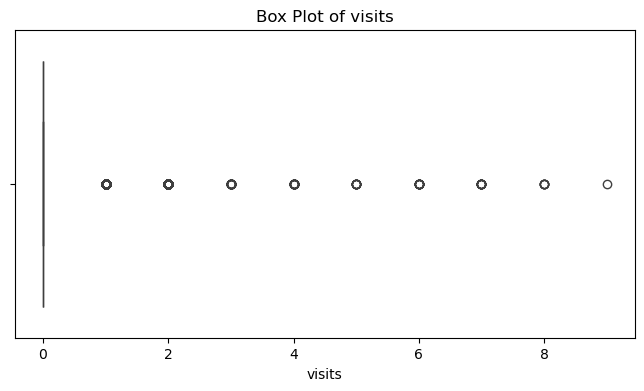

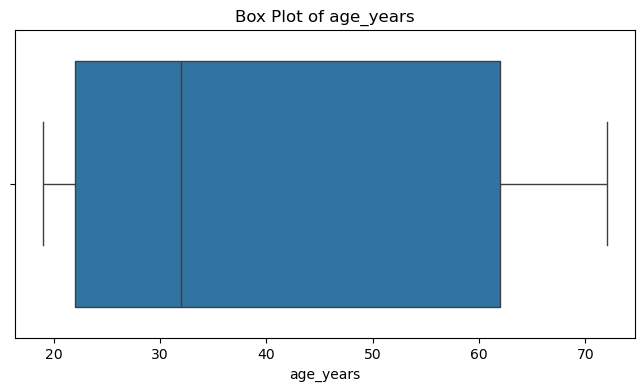

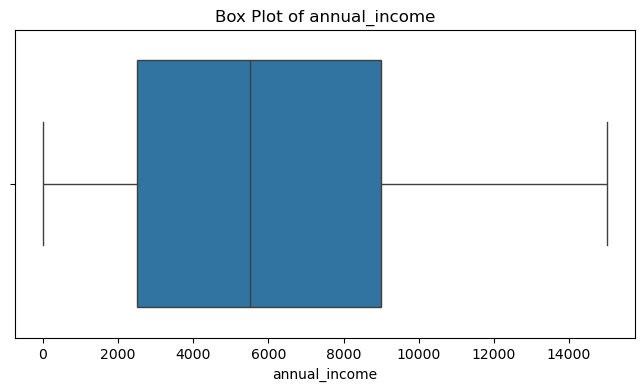

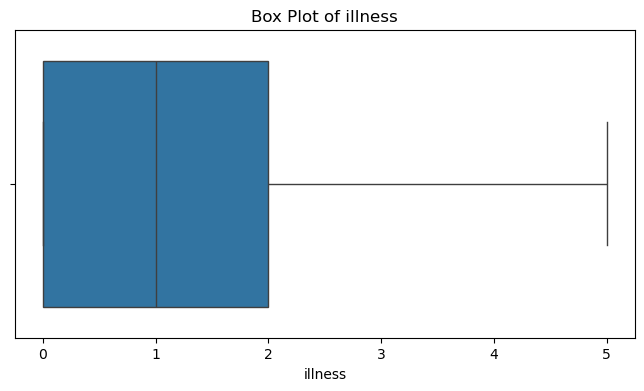

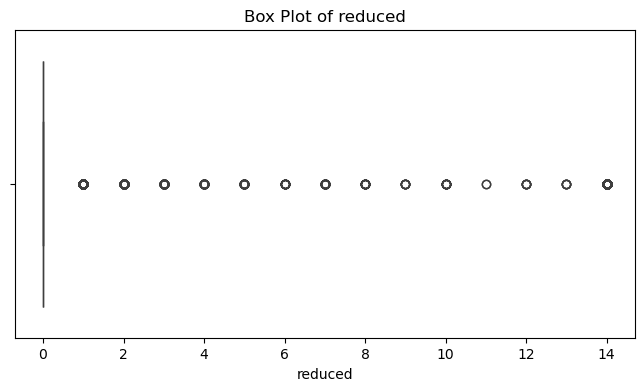

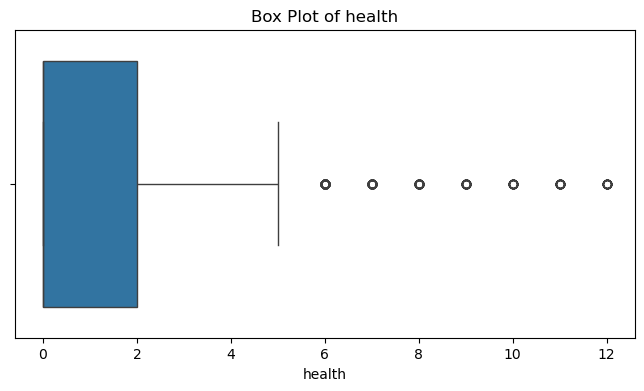

In [26]:
# Identify potential outliers and examine the distribution of each numerical variable using box plots

numeric_cols = [
    'visits',
    'age_years',
    'annual_income',
    'illness',
    'reduced',
    'health'
]

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Box Plot of {col}')
    plt.xlabel(col)
    plt.show()

### <font color='green'>**Outlier Assessment:**</font>
### <font color='green'>Potential outliers were identified using boxplots. Observations lying beyond the boxplot whiskers were considered potential outliers for screening purposes. These observations were not automatically removed, as extreme values may represent valid differences in healthcare utilization, income, health conditions, or activity levels. Therefore, outlier detection was used to identify unusual observations rather than remove records without evidence of data-entry or measurement errors.</font>

> ### **4. DOCTOR VISIT DISTRIBUTION ANALYSIS**
### <font color = 'red'>**Analytical Questions:**
### <font color = 'red'>**1. How is doctor visit utilization distributed across individuals?**</font>

### **4.1 How is doctor visit utilization distributed across individuals?**

In [27]:
# Count the number of individuals for each number of doctor visits and sort by visit count to show the distribution in logical order

visit_counts = df['visits'].value_counts().sort_index()

# Calculate the percentage distribution of individuals across different numbers of doctor visits

visit_distribution = pd.DataFrame({
    'Number of Individuals': visit_counts,
    'Percentage': (visit_counts / len(df) * 100).round(2)
})

display(visit_distribution)

,Number of Individuals,Percentage
visits,,
0,4141,79.79
1,782,15.07
2,174,3.35
3,30,0.58
4,24,0.46
5,9,0.17
6,12,0.23
7,12,0.23
8,5,0.10


In [28]:
# Count individuals with no doctor visits and those with at least one doctor visit during the observation period

zero_visits = (df['visits'] == 0).sum()
at_least_one_visit = (df['visits'] > 0).sum()

In [29]:
# Calculate the percentage of individuals in each utilization category

print("Individuals with zero doctor visits:", zero_visits)

print("Individuals with at least one doctor visit:", at_least_one_visit)

print("Percentage with zero doctor visits:", round(zero_visits / len(df) * 100, 2), "%")

print("Percentage with at least one doctor visit:", round(at_least_one_visit / len(df) * 100, 2), "%")

Individuals with zero doctor visits: 4141
Individuals with at least one doctor visit: 1049
Percentage with zero doctor visits: 79.79 %
Percentage with at least one doctor visit: 20.21 %


In [30]:
# Identify the most frequently reported number of doctor visits

most_common_visits = df['visits'].mode()[0]
most_common_count = (df['visits'] == most_common_visits).sum()

print("Most common number of doctor visits:", most_common_visits)
print("Number of individuals:", most_common_count)

Most common number of doctor visits: 0
Number of individuals: 4141


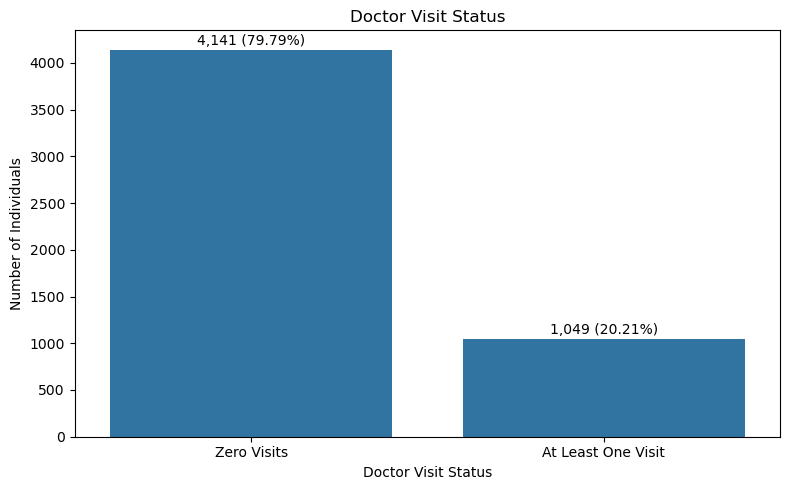

In [31]:
# Compare the number and percentage of individuals with zero doctor visits versus those who reported at least one doctor visit

visit_status = pd.Series({
    'Zero Visits': (df['visits'] == 0).sum(),
    'At Least One Visit': (df['visits'] > 0).sum()
})

plt.figure(figsize=(8, 5))

ax = sns.barplot(x=visit_status.index, y=visit_status.values)

plt.title('Doctor Visit Status')
plt.xlabel('Doctor Visit Status')
plt.ylabel('Number of Individuals')

for i, count in enumerate(visit_status.values):
    percentage = count / len(df) * 100
    ax.text(i, count + 50, f'{count:,} ({percentage:.2f}%)', ha='center')

plt.tight_layout()
plt.show()

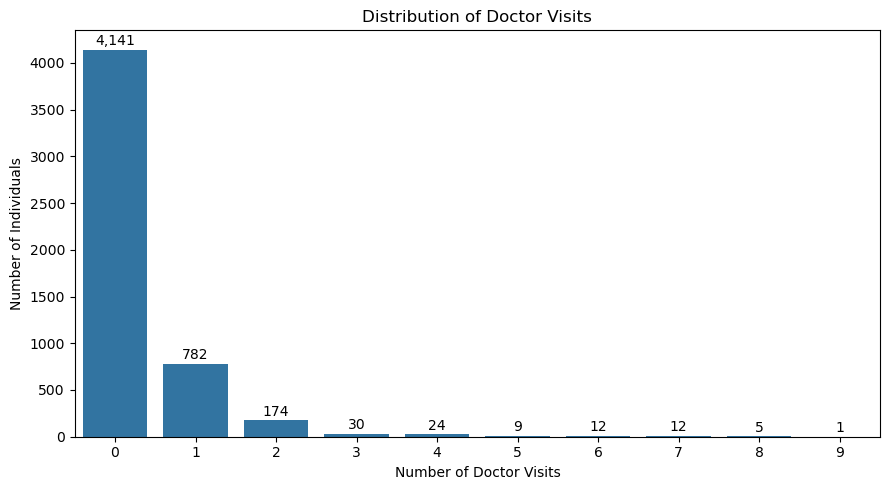

In [32]:
# Visualize the frequency of each doctor visit count to examine the overall distribution of healthcare utilization

plt.figure(figsize=(9, 5))

ax = sns.barplot(x=visit_counts.index,  y=visit_counts.values)

plt.title('Distribution of Doctor Visits')
plt.xlabel('Number of Doctor Visits')
plt.ylabel('Number of Individuals')

for i, count in enumerate(visit_counts.values):
    ax.text(i, count + 50, f'{count:,}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>Doctor visit utilization was highly concentrated at zero. Out of 5,190 individuals, 4,141 (79.79%) reported no doctor visits, while 1,049 (20.21%) reported at least one visit during the observation period. Zero visits was also the most common observation. The frequency of individuals generally decreased as the number of visits increased, indicating a strongly right-skewed utilization distribution.</font>

> ### **5. DEMOGRAPHIC ANALYSIS**
### <font color = 'red'>**Analytical Questions:**</font>
### <font color = 'red'>**1. How do doctor visits differ by gender?**</font>
### <font color = 'red'>**2. What is the gender composition of each utilization group?**</font>
### <font color = 'red'>**3. How does doctor utilization vary across different age groups?**</font>
### <font color = 'red'>**4. What is the age-group composition of each utilization group?**</font>

### **5.1 How do doctor visits differ by gender?**

In [33]:
df['gender'].value_counts()

gender
female    2702
male      2488
Name: count, dtype: int64

In [34]:
# Group individuals by gender and calculate key doctor-visit utilization measures for each group

gender_summary = df.groupby('gender').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage of individuals who reported at least one visit

gender_summary['Visit_Percentage'] = (
    gender_summary['Individuals_With_Visit']
    / gender_summary['Individuals'] * 100
).round(2)

gender_summary['Mean_Visits'] = gender_summary['Mean_Visits'].round(2)

display(gender_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
gender,,,,,
female,2702,0.36,0.0,660,24.43
male,2488,0.24,0.0,389,15.64


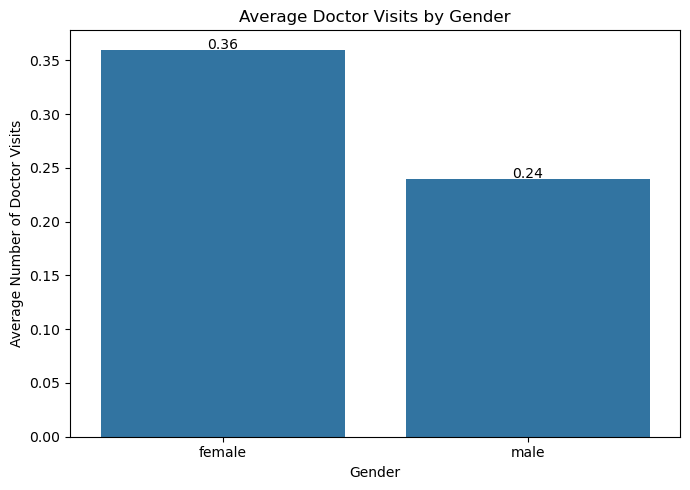

In [35]:
# Compare the average number of doctor visits across gender groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=gender_summary.reset_index(),
    x='gender',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(gender_summary['Mean_Visits']):
    ax.text(i, value + 0.001, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>Doctor visit utilization differed by gender, with female individuals recording a higher average number of doctor visits (0.36) compared with male individuals (0.24). This indicates greater observed doctor visit utilization among females in the dataset.</font>

### **5.2 What is the gender composition of each utilization group?**

In [36]:
# Calculate the percentage distribution of gender within each doctor visit utilization group

gender_utilization = pd.crosstab(
    df['visit_group'],
    df['gender'],
    normalize='index'
) * 100

gender_utilization = gender_utilization.round(2)

display(gender_utilization)

gender,female,male
visit_group,,
No visits,49.31,50.69
1–2 visits,63.60,36.40
3+ visits,55.91,44.09


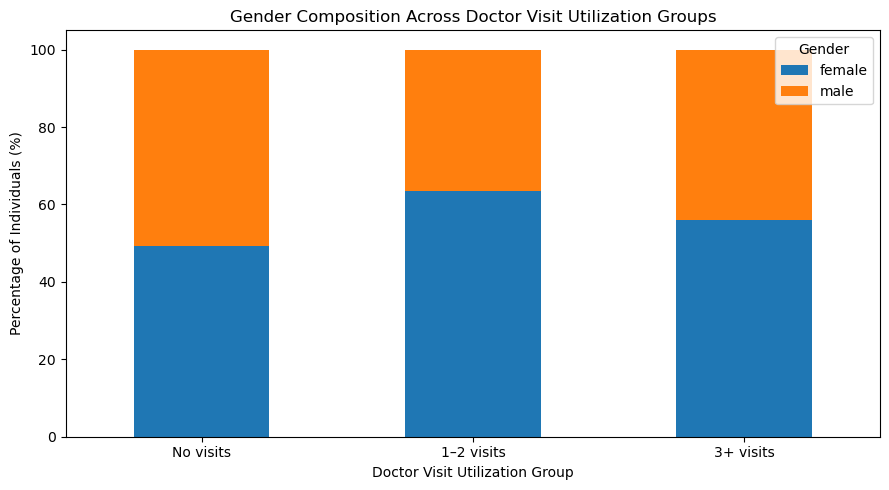

In [37]:
# Visualize the gender composition of each doctor visit utilization group using a 100% stacked bar chart

gender_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Gender Composition Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Gender')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The gender composition varies across doctor visit utilization groups. Females represented about 49% of individuals with no visits, increasing to approximately 64% in the 1–2 visits group and 56% in the 3+ visits group. This indicates that females had greater representation among individuals reporting doctor visits, particularly in the 1–2 visits group.</font>

### **5.3 How does doctor utilization vary across different age groups?**

In [38]:
df['age_group'].value_counts().sort_index()

age_group
0-18        0
19-30    2488
31-45     573
46-60     676
61+      1453
Name: count, dtype: int64

In [39]:
# Calculate doctor visit statistics and the percentage of individuals with at least one doctor visit for each age group

age_summary = df.groupby('age_group', observed=True).agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage of individuals with at least one doctor visit

age_summary['Visit_Percentage'] = (
    age_summary['Individuals_With_Visit']
    / age_summary['Individuals'] * 100
).round(2)

age_summary['Mean_Visits'] = age_summary['Mean_Visits'].round(2)

display(age_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
age_group,,,,,
19-30,2488,0.22,0.0,375,15.07
31-45,573,0.26,0.0,98,17.10
46-60,676,0.37,0.0,156,23.08
61+,1453,0.43,0.0,420,28.91


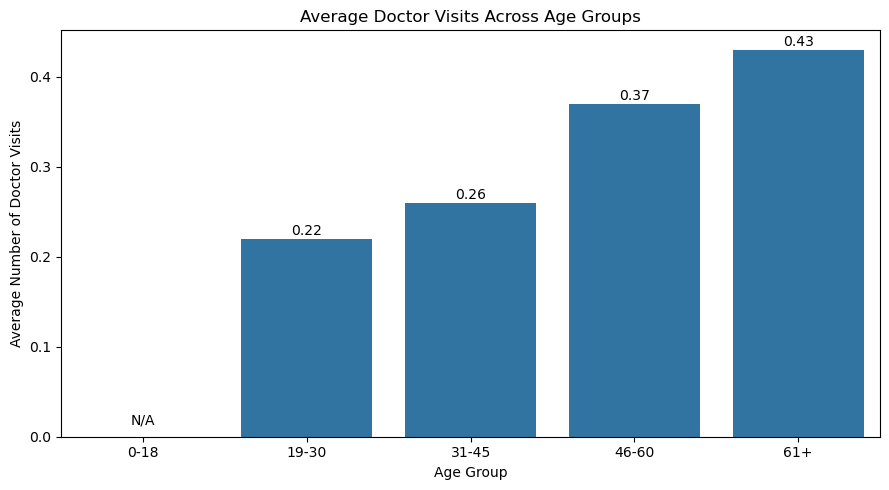

In [40]:
# Compare average doctor visits across age groups

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=age_summary.reset_index(),
    x='age_group',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits Across Age Groups')
plt.xlabel('Age Group')
plt.ylabel('Average Number of Doctor Visits')

# Add 0 above the empty 0–18 age group

ax.text(
    0,
    0.01,
    'N/A',
    ha='center',
    va='bottom'
)

# Add the average visit values above the actual bars

for i, value in enumerate(age_summary['Mean_Visits'].dropna(), start=1):
    ax.text(
        i,
        value + 0.001,
        f'{value:.2f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

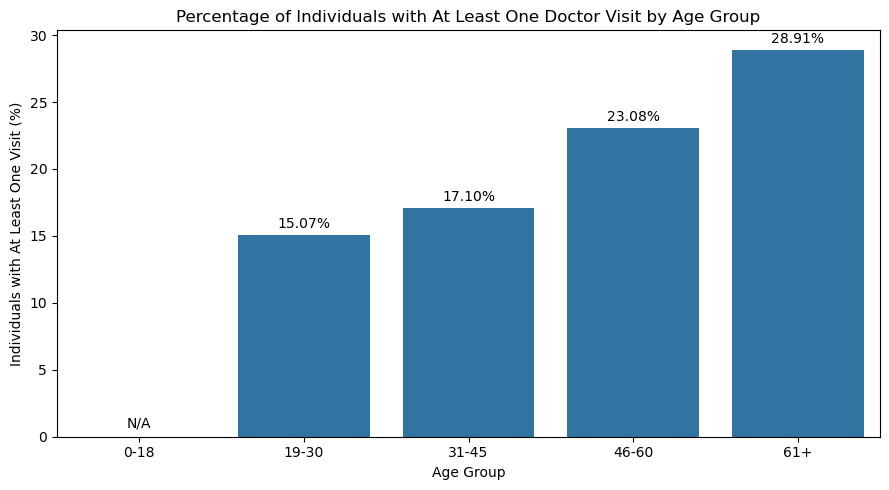

In [41]:
# Compare the percentage of individuals with at least one doctor visit across age groups

plt.figure(figsize=(9, 5))

age_visit_percentage = age_summary['Visit_Percentage']

ax = sns.barplot(
    x=age_visit_percentage.index,
    y=age_visit_percentage.values
)

plt.title('Percentage of Individuals with At Least One Doctor Visit by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Individuals with At Least One Visit (%)')

# Indicate that the 0–18 age group has no observations

ax.text(
    0,
    0.5,
    'N/A',
    ha='center',
    va='bottom'
)

# Add the percentage values above the actual bars

for i, value in enumerate(age_visit_percentage.dropna(), start=1):
    ax.text(
        i,
        value + 0.3,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>Doctor visit utilization increased across the age groups. Average doctor visits rose from 0.22 among individuals aged 19–30 to 0.43 among those aged 61+. Similarly, the proportion reporting at least one doctor visit increased from 15.07% to 28.91%. The median remained zero across all age groups because doctor visits were highly concentrated at zero. Overall, older age groups showed greater observed healthcare utilization in this dataset.</font>

### **5.4 What is the age-group composition of each utilization group?**

In [42]:
# Calculate the percentage distribution of age groups within each doctor visit utilization group

age_utilization = pd.crosstab(
    df['visit_group'],
    df['age_group'],
    normalize='index'
) * 100

age_utilization = age_utilization.round(2)

display(age_utilization)

age_group,19-30,31-45,46-60,61+
visit_group,,,,
No visits,51.03,11.47,12.56,24.95
1–2 visits,36.09,9.00,14.54,40.38
3+ visits,32.26,12.90,18.28,36.56


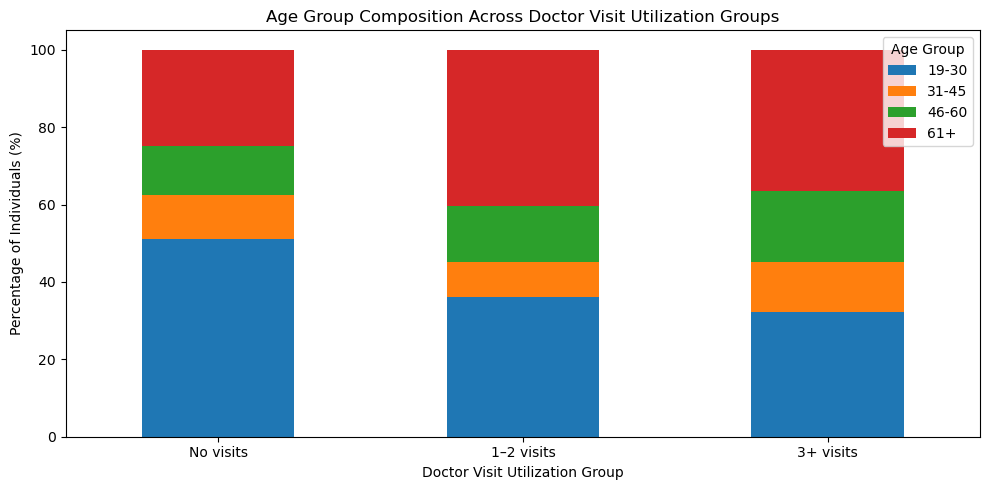

In [43]:
# Visualize the age-group composition of each doctor visit utilization group using a 100% stacked bar chart

age_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Age Group Composition Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Age Group')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that younger individuals (19–30 years) are more prevalent among those with no doctor visits, while older individuals (61+ years) make up the largest proportion of those with 1–2 or 3+ visits. This suggests higher doctor visit utilization among older age groups.</font>

> ### **6. SOCIOECONOMIC ANALYSIS**
### <font color = 'red'>**Analytical Questions:**</font>
### <font color = 'red'>**1. How does doctor utilization vary across income levels?**</font>
### <font color = 'red'>**2. What is the income-group composition of each utilization group?**</font>

### **6.1 How does doctor utilization vary across income levels?**

In [44]:
print(df['annual_income'].describe())

count     5190.000000
mean      5831.599229
std       3689.066984
min          0.000000
25%       2500.000000
50%       5500.000000
75%       9000.000000
max      15000.000000
Name: annual_income, dtype: float64


In [45]:
print("Minimum annual income:", df['annual_income'].min())
print("Maximum annual income:", df['annual_income'].max())

Minimum annual income: 0.0
Maximum annual income: 15000.0


In [46]:
df['income_group'].value_counts().sort_index()

income_group
Low Income             1638
Lower-Middle Income    1329
Upper-Middle Income    1485
High Income             738
Name: count, dtype: int64

In [47]:
# Group individuals into income quartiles and compare doctor-visit utilization across the resulting income groups

income_summary = df.groupby('income_group', observed=True).agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage reporting at least one doctor visit

income_summary['Visit_Percentage'] = (
    income_summary['Individuals_With_Visit']
    / income_summary['Individuals'] * 100
).round(2)

income_summary['Mean_Visits'] = income_summary['Mean_Visits'].round(2)

display(income_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
income_group,,,,,
Low Income,1638,0.40,0.0,420,25.64
Lower-Middle Income,1329,0.31,0.0,267,20.09
Upper-Middle Income,1485,0.23,0.0,246,16.57
High Income,738,0.22,0.0,116,15.72


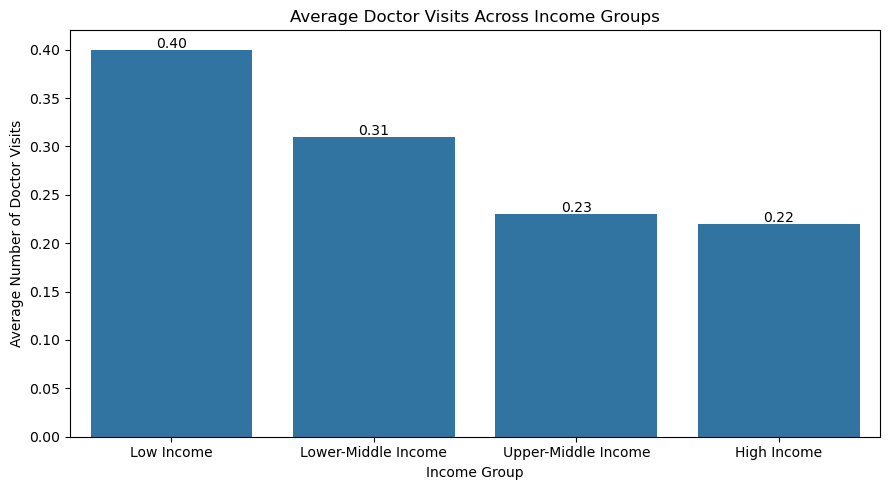

In [48]:
# Compare average doctor visits across income groups

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=income_summary.reset_index(),
    x='income_group',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits Across Income Groups')
plt.xlabel('Income Group')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(income_summary['Mean_Visits']):
    ax.text(i, value + 0.002, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

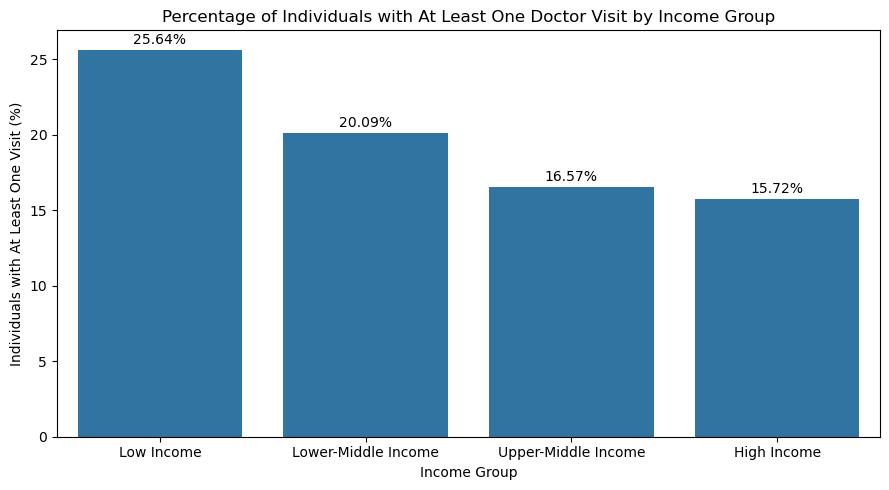

In [49]:
# Compare the percentage of individuals with at least one doctor visit across income groups

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=income_summary.reset_index(),
    x='income_group',
    y='Visit_Percentage'
)

plt.title('Percentage of Individuals with At Least One Doctor Visit by Income Group')
plt.xlabel('Income Group')
plt.ylabel('Individuals with At Least One Visit (%)')

for i, value in enumerate(income_summary['Visit_Percentage']):
    ax.text(i, value + 0.4, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>Doctor visit utilization decreased across income groups. Average doctor visits declined from 0.40 among low-income individuals to 0.22 among high-income individuals. Similarly, the proportion reporting at least one doctor visit decreased from 25.64% to 15.72%. The median remained zero across all income groups, indicating that at least half of the individuals in each group had no doctor visits. Overall, low-income individuals showed greater observed healthcare utilization in this dataset.</font>

### **6.2 What is the income-group composition of each utilization group?**

In [50]:
# Calculate the percentage distribution of income groups within each doctor visit utilization group

income_utilization = pd.crosstab(
    df['visit_group'],
    df['income_group'],
    normalize='index'
) * 100

income_utilization = income_utilization.round(2)

display(income_utilization)

income_group,Low Income,Lower-Middle Income,Upper-Middle Income,High Income
visit_group,,,,
No visits,29.41,25.65,29.92,15.02
1–2 visits,40.27,24.79,23.85,11.09
3+ visits,37.63,32.26,19.35,10.75


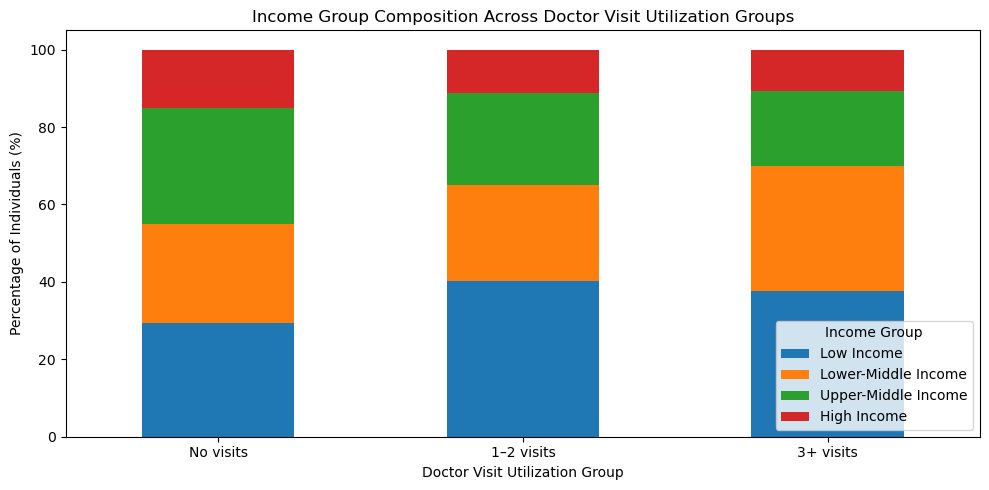

In [51]:
# Visualize the income-group composition of each doctor visit utilization group using a 100% stacked bar chart

income_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Income Group Composition Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Income Group')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that low-income individuals make up the largest share of those with 3+ doctor visits, while upper-middle-income individuals represent a larger share of those with no visits. Overall, lower-income groups account for a greater proportion of individuals with frequent doctor visits, whereas higher-income groups contribute less.</font>

> ### **7. HEALTH BURDEN ANALYSIS**
### <font color = 'red'>**Analytical Questions:**</font>
### <font color = 'red'>**1. How does the number of illnesses relate to doctor visits?**</font>
### <font color = 'red'>**2. How does the average number of illnesses vary across utilization groups?**</font>
### <font color = 'red'>**3. How does reduced activity relate to doctor visits?**</font>
### <font color = 'red'>**4. How does average reduced activity vary across utilization groups?**</font>
### <font color = 'red'>**5. How does health status vary with doctor visits?**</font>
### <font color = 'red'>**6. How does the average health score vary across utilization groups?**</font>

### **7.1 How does the number of illnesses relate to doctor visits?**

In [52]:
df['illness'].value_counts().sort_index()

illness
0    1554
1    1638
2     946
3     542
4     274
5     236
Name: count, dtype: int64

In [53]:
# Group individuals by the number of illnesses and calculate doctor-visit utilization measures for each illness level

illness_summary = df.groupby('illness').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median')
)

illness_summary['Mean_Visits'] = illness_summary['Mean_Visits'].round(2)

display(illness_summary)

,Individuals,Mean_Visits,Median_Visits
illness,,,
0,1554,0.08,0.0
1,1638,0.30,0.0
2,946,0.40,0.0
3,542,0.42,0.0
4,274,0.58,0.0
5,236,0.81,0.0


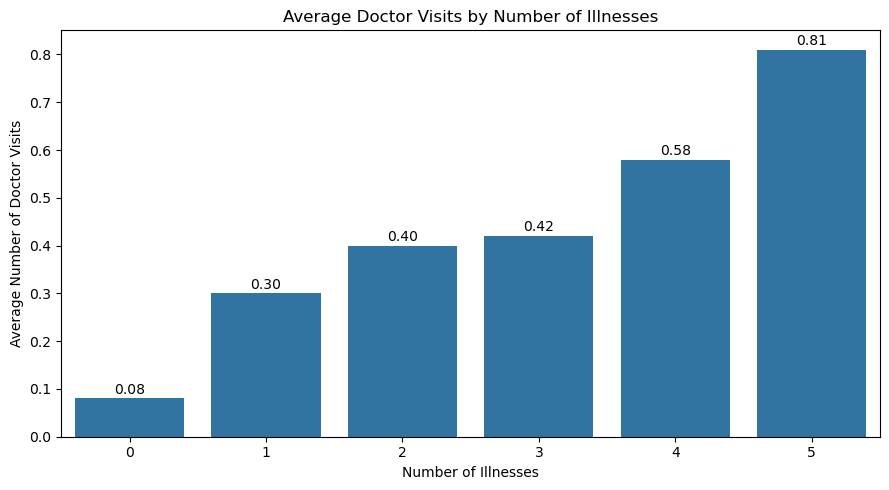

In [54]:
# Compare average doctor visits across different numbers of reported illnesses

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=illness_summary.reset_index(),
    x='illness',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Number of Illnesses')
plt.xlabel('Number of Illnesses')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(illness_summary['Mean_Visits']):
    ax.text(i, value + 0.01, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>Doctor visit utilization varied according to the number of reported illnesses. The average number of visits generally increased as the number of illnesses increased, indicating that individuals reporting a greater illness burden tended to have higher observed doctor utilization. However, this is an observed association and does not establish a causal relationship.</font>

### **7.2 How does the average number of illnesses vary across utilization groups?**

In [55]:
# Compare the average and median number of illnesses within each doctor visit utilization group

illness_utilization = df.groupby(
    'visit_group',
    observed=True
).agg(
    Individuals=('illness', 'count'),
    Mean_Illness=('illness', 'mean'),
    Median_Illness=('illness', 'median')
).reindex(visit_group_order)

illness_utilization['Mean_Illness'] = illness_utilization['Mean_Illness'].round(2)
illness_utilization['Median_Illness'] = illness_utilization['Median_Illness'].round(2)

display(illness_utilization)

,Individuals,Mean_Illness,Median_Illness
visit_group,,,
No visits,4141,1.26,1.0
1–2 visits,956,2.10,2.0
3+ visits,93,2.42,2.0


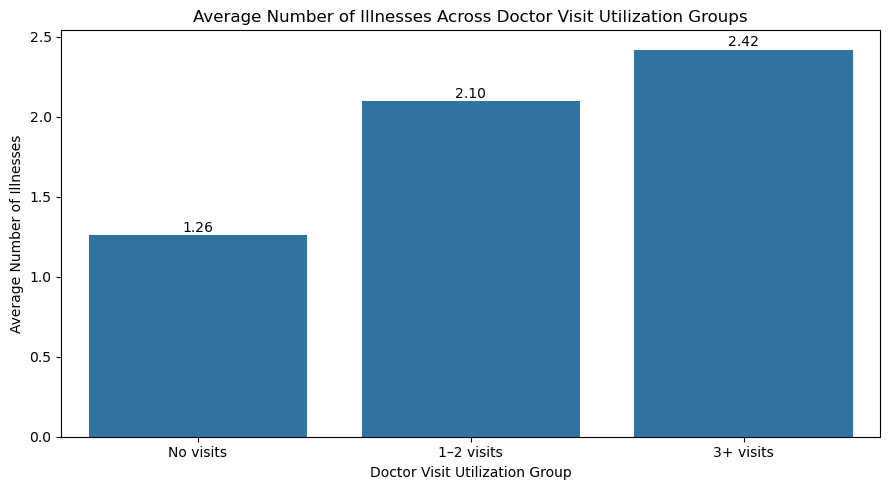

In [56]:
# Visualize the average number of illnesses across doctor visit utilization groups

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=illness_utilization.reset_index(),
    x='visit_group',
    y='Mean_Illness'
)

plt.title('Average Number of Illnesses Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Average Number of Illnesses')

for i, value in enumerate(illness_utilization['Mean_Illness']):
    ax.text(i, value + 0.02, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that the average number of illnesses increases with doctor visit utilization, rising from 1.26 among individuals with no visits to 2.42 among those with 3+ visits. Overall, individuals with a higher illness burden tend to have greater observed healthcare utilization in this dataset.</font>

### **7.3 How does reduced activity relate to doctor visits?**

In [57]:
df['reduced'].value_counts().sort_index()

reduced
0     4454
1      177
2      108
3       74
4       45
5       40
6       17
7       38
8       17
9        7
10      12
11       2
12       6
13       5
14     188
Name: count, dtype: int64

In [58]:
# Calculate doctor visit statistics for each number of days with reduced activity

reduced_summary = df.groupby('reduced').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median')
)

reduced_summary['Mean_Visits'] = reduced_summary['Mean_Visits'].round(2)

display(reduced_summary)

,Individuals,Mean_Visits,Median_Visits
reduced,,,
0,4454,0.18,0.0
1,177,0.36,0.0
2,108,0.57,0.0
3,74,1.09,1.0
4,45,0.80,1.0
5,40,1.27,1.0
6,17,1.18,1.0
7,38,1.18,1.0
8,17,1.18,1.0


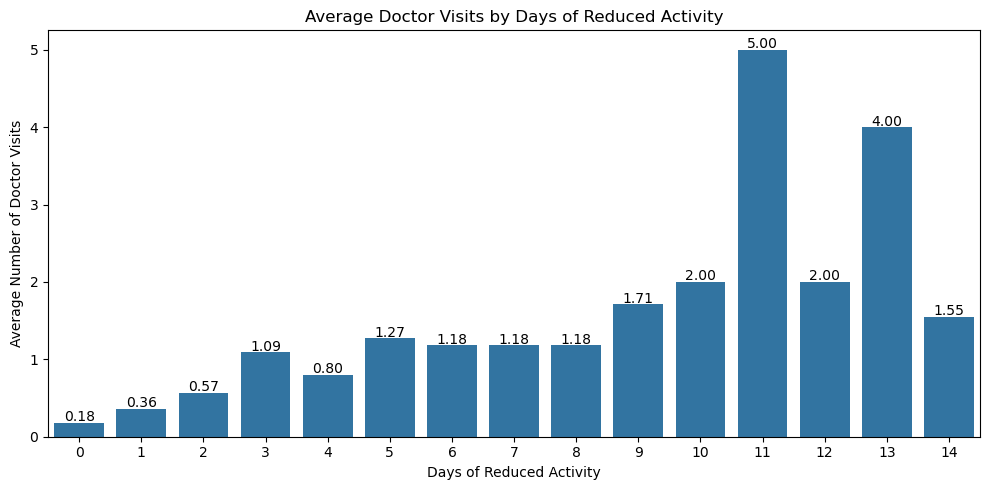

In [59]:
# Compare average doctor visits across different levels of reduced activity

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=reduced_summary.reset_index(),
    x='reduced',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Days of Reduced Activity')
plt.xlabel('Days of Reduced Activity')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(reduced_summary['Mean_Visits']):
    ax.text(i, value + 0.02, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>Doctor visits varied across the number of days of reduced activity. Individuals reporting more days of reduced activity generally showed higher observed utilization, suggesting that greater short-term activity limitation was associated with increased doctor visits in this dataset.</font>

### **7.4 How does average reduced activity vary across utilization groups?**

In [60]:
# Calculate average and median days of reduced activity for each doctor visit utilization group

reduced_utilization = df.groupby(
    'visit_group',
    observed=True
).agg(
    Individuals=('reduced', 'count'),
    Mean_Reduced=('reduced', 'mean'),
    Median_Reduced=('reduced', 'median')
).reindex(visit_group_order)

reduced_utilization['Mean_Reduced'] = reduced_utilization['Mean_Reduced'].round(2)
reduced_utilization['Median_Reduced'] = reduced_utilization['Median_Reduced'].round(2)

display(reduced_utilization)

,Individuals,Mean_Reduced,Median_Reduced
visit_group,,,
No visits,4141,0.43,0.0
1–2 visits,956,2.08,0.0
3+ visits,93,7.75,7.0


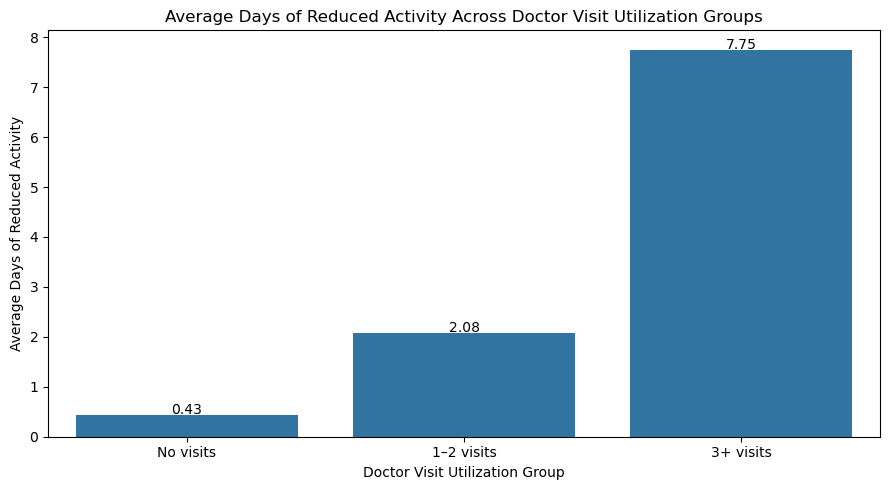

In [61]:
# Compare average days of reduced activity across doctor visit utilization groups

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=reduced_utilization.reset_index(),
    x='visit_group',
    y='Mean_Reduced'
)

plt.title('Average Days of Reduced Activity Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Average Days of Reduced Activity')

for i, value in enumerate(reduced_utilization['Mean_Reduced']):
    ax.text(i, value + 0.02, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that average days of reduced activity increase with doctor visit utilization, rising from 0.43 days among individuals with no visits to 7.75 days among those with 3+ visits. Overall, greater healthcare utilization is associated with more days of reduced activity in this dataset.</font>

### **7.5 How does health status vary with doctor visits?**

In [62]:
# Calculate average and median health scores for each number of doctor visits

health_summary = df.groupby('visits').agg(
    Individuals=('health', 'count'),
    Mean_Health=('health', 'mean'),
    Median_Health=('health', 'median')
)

health_summary['Mean_Health'] = health_summary['Mean_Health'].round(2)

display(health_summary)

,Individuals,Mean_Health,Median_Health
visits,,,
0,4141,1.02,0.0
1,782,1.77,1.0
2,174,2.40,1.0
3,30,2.97,2.0
4,24,2.67,2.0
5,9,2.78,1.0
6,12,4.00,3.5
7,12,2.67,1.5
8,5,3.40,4.0


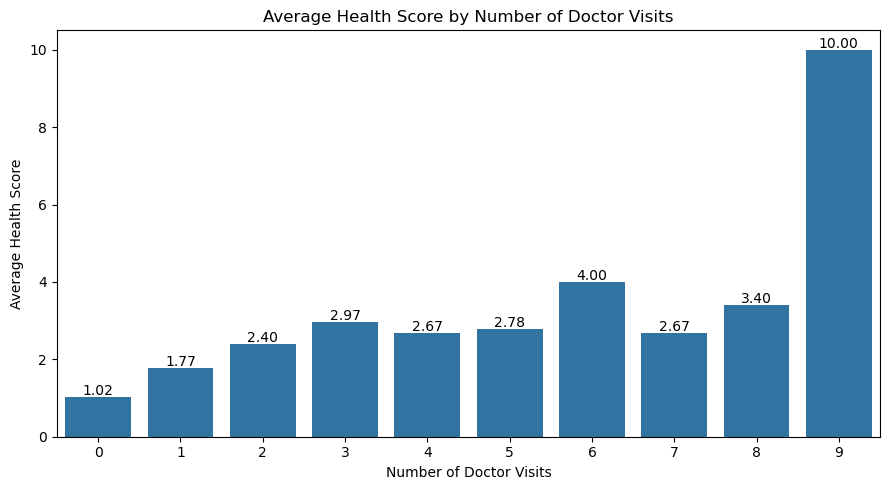

In [63]:
# Compare average health scores across different numbers of doctor visits

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=health_summary.reset_index(),
    x='visits',
    y='Mean_Health'
)

plt.title('Average Health Score by Number of Doctor Visits')
plt.xlabel('Number of Doctor Visits')
plt.ylabel('Average Health Score')

for i, value in enumerate(health_summary['Mean_Health']):
    ax.text(i, value + 0.05, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that average health scores generally increase with the number of doctor visits, rising from 1.02 among individuals with no visits to 10.00 among those with nine visits. However, some fluctuations occur across visit counts, suggesting that the relationship is not consistently linear.</font>

### **7.6 How does the average health score vary across utilization groups?**

In [64]:
# Calculate average and median health scores for each doctor visit utilization group

health_utilization = df.groupby(
    'visit_group',
    observed=True
).agg(
    Individuals=('health', 'count'),
    Mean_Health=('health', 'mean'),
    Median_Health=('health', 'median')
).reindex(visit_group_order)

health_utilization['Mean_Health'] = health_utilization['Mean_Health'].round(2)
health_utilization['Median_Health'] = health_utilization['Median_Health'].round(2)

display(health_utilization)

,Individuals,Mean_Health,Median_Health
visit_group,,,
No visits,4141,1.02,0.0
1–2 visits,956,1.89,1.0
3+ visits,93,3.06,2.0


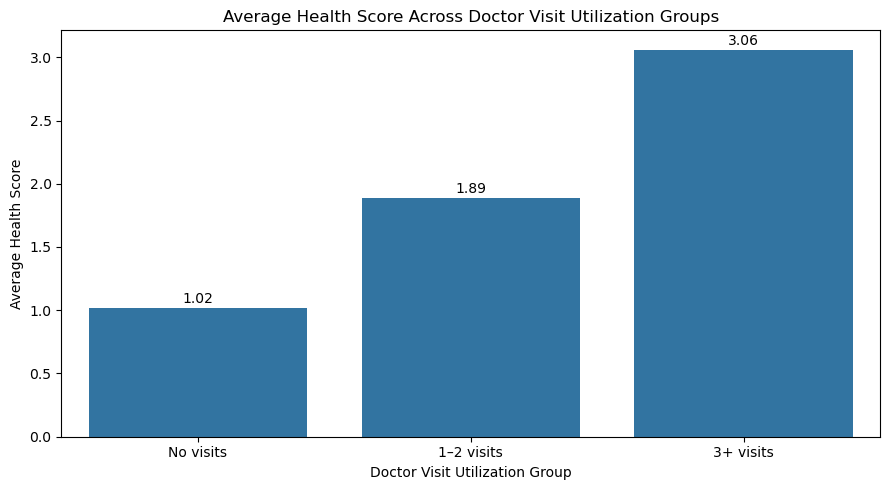

In [107]:
# Compare average health scores across doctor visit utilization groups

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=health_utilization.reset_index(),
    x='visit_group',
    y='Mean_Health'
)

plt.title('Average Health Score Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Average Health Score')

for i, value in enumerate(health_utilization['Mean_Health']):
    ax.text(i, value + 0.04, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that average health scores increase with doctor visit utilization, rising from 1.02 among individuals with no visits to 3.06 among those with 3+ visits. Overall, higher doctor visit utilization is associated with higher average health scores in this dataset.</font>

> ### **8. INSURANCE ANALYSIS**
### <font color = 'red'>**Analytical Questions:**</font>
### <font color = 'red'>**1. How do doctor visits differ by private insurance coverage?**</font>
### <font color = 'red'>**2. What is the private insurance composition of each utilization group?**</font>
### <font color = 'red'>**3. How do doctor visits differ for individuals receiving free healthcare due to low income?**</font>
### <font color = 'red'>**4. What is the healthcare-coverage composition of each utilization group based on low-income eligibility?**</font>
### <font color = 'red'>**5. How do doctor visits differ for individuals receiving free government healthcare under the freerepat category?**</font>
### <font color = 'red'>**6. What is the composition of freerepat coverage across utilization groups?**</font>

### **8.1 How do doctor visits differ by private insurance coverage?**

In [66]:
df['private'].value_counts()

private
no     2892
yes    2298
Name: count, dtype: int64

In [67]:
# Calculate doctor visit statistics and the percentage of individuals with at least one doctor visit for each private insurance group

private_summary = df.groupby('private').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage of individuals with at least one doctor visit

private_summary['Visit_Percentage'] = (
    private_summary['Individuals_With_Visit']
    / private_summary['Individuals'] * 100
).round(2)

private_summary['Mean_Visits'] = private_summary['Mean_Visits'].round(2)

display(private_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
private,,,,,
no,2892,0.31,0.0,589,20.37
yes,2298,0.29,0.0,460,20.02


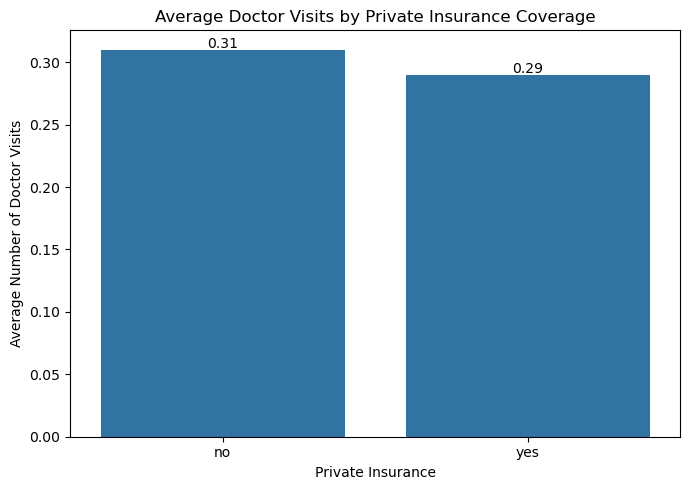

In [68]:
# Compare average doctor visits across private insurance groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=private_summary.reset_index(),
    x='private',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Private Insurance Coverage')
plt.xlabel('Private Insurance')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(private_summary['Mean_Visits']):
    ax.text(i, value + 0.001, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

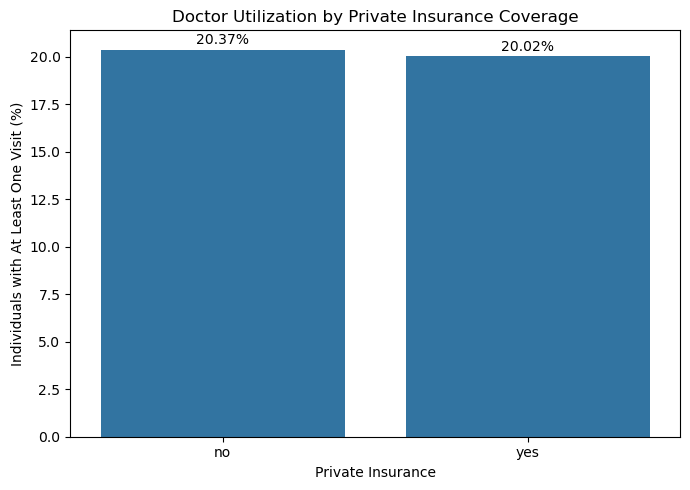

In [69]:
# Compare the percentage of individuals with at least one doctor visit across private insurance groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=private_summary.reset_index(),
    x='private',
    y='Visit_Percentage'
)

plt.title('Doctor Utilization by Private Insurance Coverage')
plt.xlabel('Private Insurance')
plt.ylabel('Individuals with At Least One Visit (%)')

for i, value in enumerate(private_summary['Visit_Percentage']):
    ax.text(i, value + 0.3, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graphs show that individuals without private insurance have slightly higher healthcare utilization, with an average of 0.31 doctor visits and 20.37% reporting at least one visit, compared with 0.29 visits and 20.02% among insured individuals. Overall, doctor visit utilization is similar across both groups, with a slight difference favoring the uninsured group in this dataset.</font>

### **8.2 What is the private insurance composition of each utilization group?**

In [70]:
# Calculate the percentage composition of private insurance status within each doctor visit utilization group

private_utilization = pd.crosstab(
    df['visit_group'],
    df['private'],
    normalize='index'
) * 100

private_utilization = private_utilization.round(2)

display(private_utilization)

private,no,yes
visit_group,,
No visits,55.61,44.39
1–2 visits,55.54,44.46
3+ visits,62.37,37.63


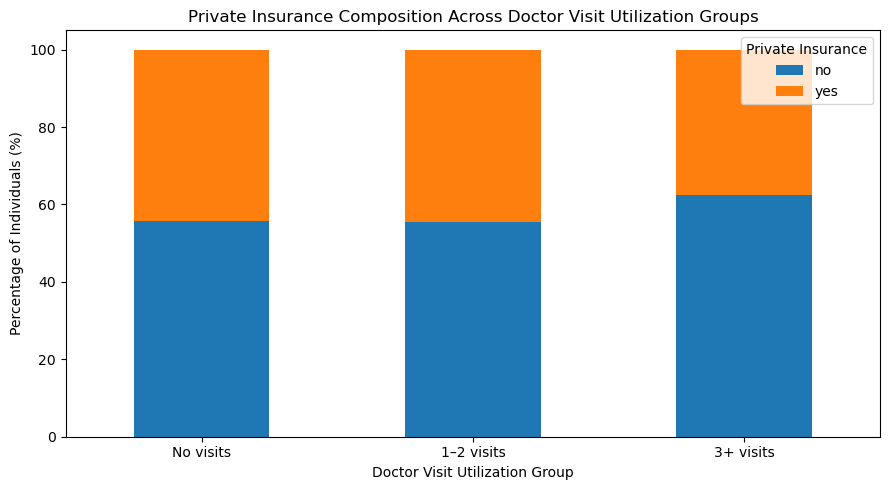

In [71]:
# Visualize private insurance composition across doctor visit utilization groups

private_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Private Insurance Composition Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Private Insurance')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that individuals without private insurance make up a slightly larger proportion of each doctor visit utilization group, particularly among those with 3+ visits. Overall, the uninsured account for a greater share of individuals across all utilization groups in this dataset.</font>

### **8.3 How do doctor visits differ for individuals receiving free healthcare due to low income?**

In [72]:
df['freepoor'].value_counts()

freepoor
no     4968
yes     222
Name: count, dtype: int64

In [73]:
# Calculate doctor visit statistics and the percentage of individuals with at least one doctor visit for each low-income healthcare coverage group

freepoor_summary = df.groupby('freepoor').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage of individuals with at least one doctor visit

freepoor_summary['Visit_Percentage'] = (
    freepoor_summary['Individuals_With_Visit']
    / freepoor_summary['Individuals'] * 100
).round(2)

freepoor_summary['Mean_Visits'] = freepoor_summary['Mean_Visits'].round(2)

display(freepoor_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
freepoor,,,,,
no,4968,0.31,0.0,1029,20.71
yes,222,0.16,0.0,20,9.01


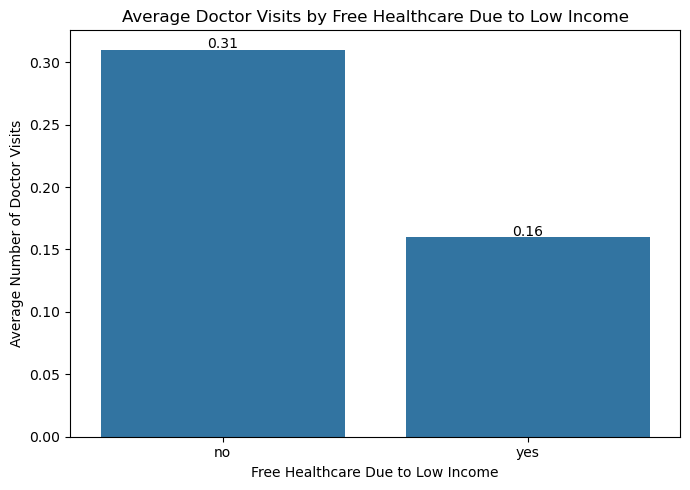

In [74]:
# Compare average doctor visits across low-income healthcare coverage groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=freepoor_summary.reset_index(),
    x='freepoor',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Free Healthcare Due to Low Income')
plt.xlabel('Free Healthcare Due to Low Income')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(freepoor_summary['Mean_Visits']):
    ax.text(i, value + 0.001, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

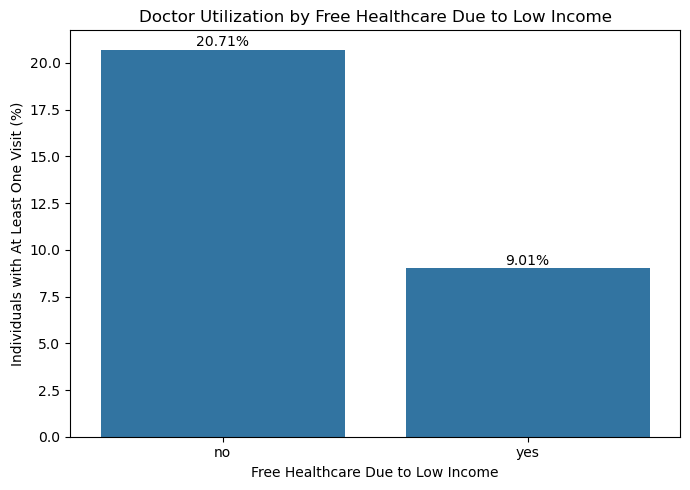

In [75]:
# Compare the percentage of individuals with at least one doctor visit across low-income healthcare coverage groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=freepoor_summary.reset_index(),
    x='freepoor',
    y='Visit_Percentage'
)

plt.title('Doctor Utilization by Free Healthcare Due to Low Income')
plt.xlabel('Free Healthcare Due to Low Income')
plt.ylabel('Individuals with At Least One Visit (%)')

for i, value in enumerate(freepoor_summary['Visit_Percentage']):
    ax.text(i, value + 0.2, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graphs shows that individuals who do not receive free healthcare due to low income have a higher average number of doctor visits (0.31) and 20.71% reporting at least one visit, compared with 0.16 visits and 9.01% among insured individuals. Overall, the group receiving free healthcare demonstrates lower observed doctor visit utilization in this dataset.</font>

### **8.4 What is the healthcare-coverage composition of each utilization group based on low-income eligibility?**

In [76]:
# Calculate the percentage composition of low-income healthcare coverage within each doctor visit utilization group

freepoor_utilization = pd.crosstab(
    df['visit_group'],
    df['freepoor'],
    normalize='index'
) * 100

freepoor_utilization = freepoor_utilization.round(2)

display(freepoor_utilization)

freepoor,no,yes
visit_group,,
No visits,95.12,4.88
1–2 visits,98.22,1.78
3+ visits,96.77,3.23


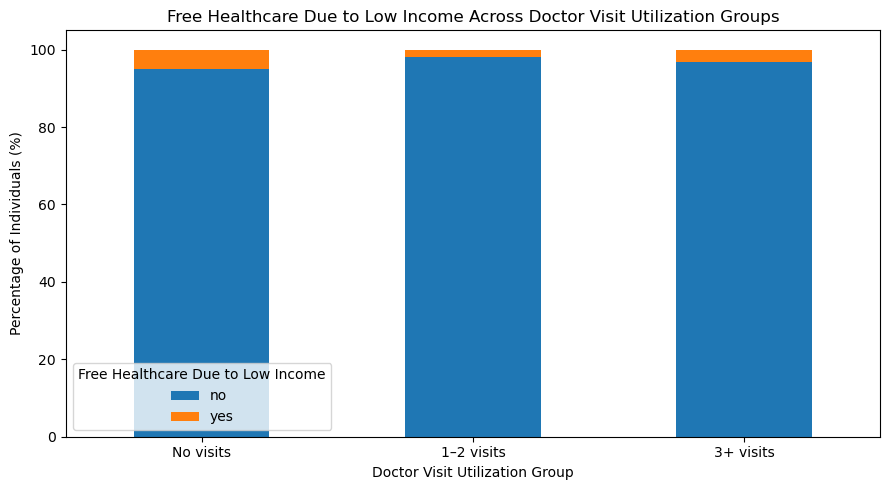

In [77]:
# Visualize low-income healthcare coverage composition across doctor visit utilization groups

freepoor_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Free Healthcare Due to Low Income Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Free Healthcare Due to Low Income')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that individuals not receiving free healthcare due to low income make up the largest proportion of each doctor visit utilization group, particularly among those with 1–2 visits (98.22%). Overall, individuals receiving free healthcare account for a very small share across all utilization groups in this dataset.</font>

### **8.5 How do doctor visits differ for individuals receiving free government healthcare under the freerepat category?**

In [78]:
df['freerepat'].value_counts()

freerepat
no     4099
yes    1091
Name: count, dtype: int64

In [79]:
# Calculate doctor visit statistics and the percentage of individuals with at least one doctor visit for each government healthcare coverage group

freerepat_summary = df.groupby('freerepat').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage of individuals with at least one doctor visit

freerepat_summary['Visit_Percentage'] = (
    freerepat_summary['Individuals_With_Visit']
    / freerepat_summary['Individuals'] * 100
).round(2)

freerepat_summary['Mean_Visits'] = freerepat_summary['Mean_Visits'].round(2)

display(freerepat_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
freerepat,,,,,
no,4099,0.26,0.0,704,17.17
yes,1091,0.47,0.0,345,31.62


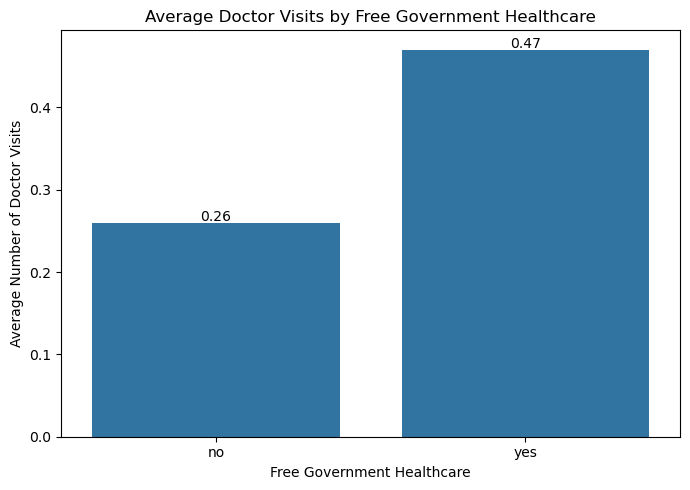

In [80]:
# Compare average doctor visits across government healthcare coverage groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=freerepat_summary.reset_index(),
    x='freerepat',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Free Government Healthcare')
plt.xlabel('Free Government Healthcare')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(freerepat_summary['Mean_Visits']):
    ax.text(i, value + 0.002, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

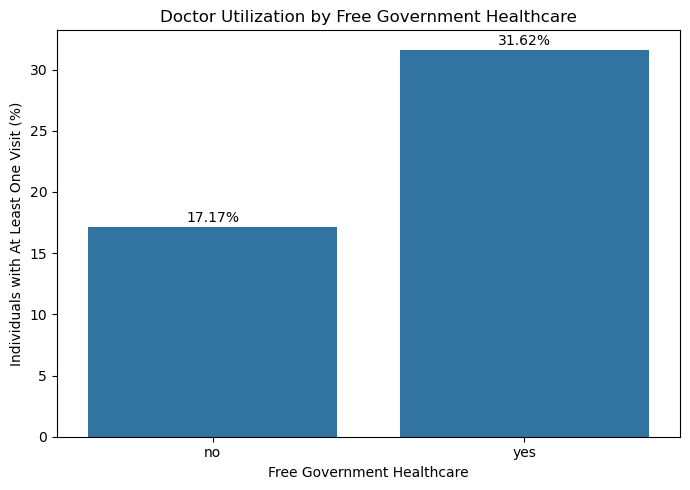

In [81]:
# Compare the percentage of individuals with at least one doctor visit across government healthcare coverage groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=freerepat_summary.reset_index(),
    x='freerepat',
    y='Visit_Percentage'
)

plt.title('Doctor Utilization by Free Government Healthcare')
plt.xlabel('Free Government Healthcare')
plt.ylabel('Individuals with At Least One Visit (%)')

for i, value in enumerate(freerepat_summary['Visit_Percentage']):
    ax.text(i, value + 0.4, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graphs show that individuals receiving free government healthcare under the freerepat category have higher healthcare utilization, with an average of 0.47 doctor visits and 31.62% reporting at least one visit, compared with 0.26 visits and 17.17% among those not receiving it. Overall, recipients demonstrate greater observed doctor visit utilization in this dataset.</font>

### **8.6 What is the composition of freerepat coverage across utilization groups?**

In [82]:
# Calculate the percentage composition of government healthcare coverage within each doctor visit utilization group

freerepat_utilization = pd.crosstab(
    df['visit_group'],
    df['freerepat'],
    normalize='index'
) * 100

freerepat_utilization = freerepat_utilization.round(2)

display(freerepat_utilization)

freerepat,no,yes
visit_group,,
No visits,81.99,18.01
1–2 visits,66.63,33.37
3+ visits,72.04,27.96


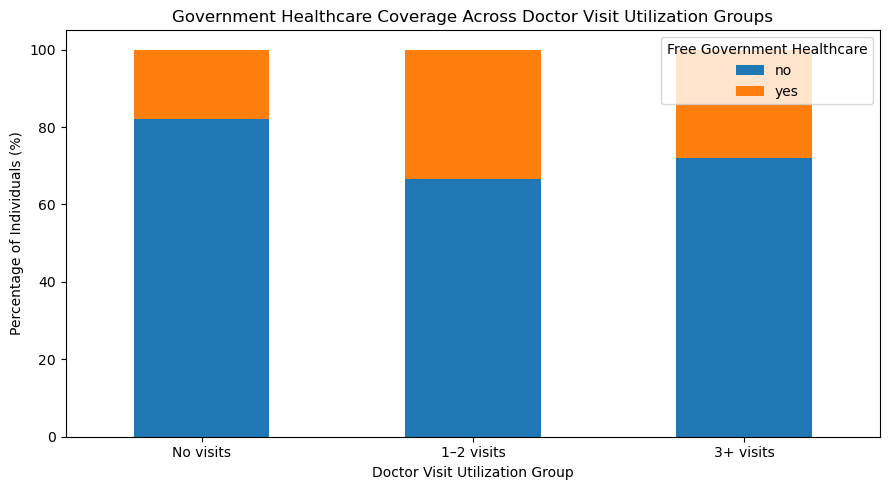

In [83]:
# Visualize government healthcare coverage composition across doctor visit utilization groups

freerepat_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Government Healthcare Coverage Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Free Government Healthcare')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that individuals not receiving free government healthcare under the freerepat category make up the majority of each doctor visit utilization group. However, recipients account for a larger proportion of individuals with 1–2 visits (33.37%) and 3+ visits (27.96%) than those with no visits (18.01%). Overall, recipients represent a greater share of individuals with doctor visits than of those with no visits in this dataset.</font>

> ### **9. CHRONIC CONDITION ANALYSIS**
### <font color = 'red'>**Analytical Questions:**</font>
### <font color = 'red'>**1. How do doctor visits differ for individuals with non-limiting chronic conditions?**</font>
### <font color = 'red'>**2. What is the composition of non-limiting chronic-condition status across utilization groups?**</font>
### <font color = 'red'>**3. How do doctor visits differ for individuals with activity-limiting chronic conditions?**</font>
### <font color = 'red'>**4. What is the composition of activity-limiting chronic-condition status across utilization groups?**</font>
### <font color = 'red'>**5. How do healthcare utilization patterns vary across combined chronic-condition groups?**</font>
### <font color = 'red'>**6. What is the chronic-condition composition of each utilization group?**</font>

### **9.1 How do doctor visits differ for individuals with non-limiting chronic conditions?**

In [84]:
df['nchronic'].value_counts()

nchronic
no     3098
yes    2092
Name: count, dtype: int64

In [85]:
# Calculate doctor visit statistics and the percentage of individuals with at least one doctor visit for each non-limiting chronic condition group

nchronic_summary = df.groupby('nchronic').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage of individuals with at least one doctor visit

nchronic_summary['Visit_Percentage'] = (
    nchronic_summary['Individuals_With_Visit']
    / nchronic_summary['Individuals'] * 100
).round(2)

nchronic_summary['Mean_Visits'] = (
    nchronic_summary['Mean_Visits'].round(2)
)

display(nchronic_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
nchronic,,,,,
no,3098,0.27,0.0,554,17.88
yes,2092,0.35,0.0,495,23.66


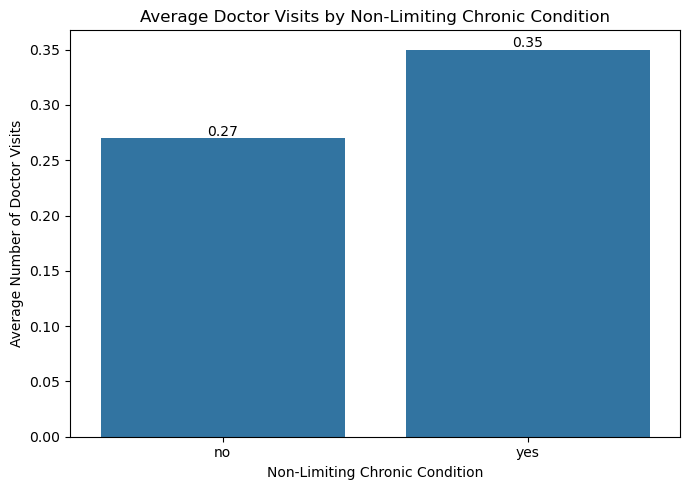

In [86]:
# Compare average doctor visits across non-limiting chronic condition groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=nchronic_summary.reset_index(),
    x='nchronic',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Non-Limiting Chronic Condition')
plt.xlabel('Non-Limiting Chronic Condition')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(nchronic_summary['Mean_Visits']):
    ax.text(i, value + 0.002, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

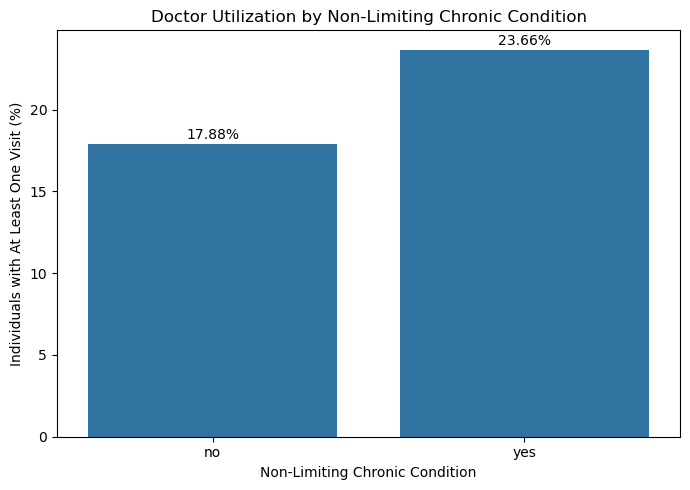

In [87]:
# Compare the percentage of individuals with at least one doctor visit across non-limiting chronic condition groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=nchronic_summary.reset_index(),
    x='nchronic',
    y='Visit_Percentage'
)

plt.title('Doctor Utilization by Non-Limiting Chronic Condition')
plt.xlabel('Non-Limiting Chronic Condition')
plt.ylabel('Individuals with At Least One Visit (%)')

for i, value in enumerate(nchronic_summary['Visit_Percentage']):
    ax.text(i, value + 0.3, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graphs show that individuals with non-limiting chronic conditions have higher healthcare utilization, with an average of 0.35 doctor visits and 23.66% reporting at least one visit, compared with 0.27 visits and 17.88% among those without such conditions. Overall, individuals with non-limiting chronic conditions demonstrate greater observed doctor visit utilization in this dataset.</font>

### **9.2 What is the composition of non-limiting chronic-condition status across utilization groups?**

In [88]:
# Calculate the percentage composition of non-limiting chronic condition status within each doctor visit utilization group

nchronic_utilization = pd.crosstab(
    df['visit_group'],
    df['nchronic'],
    normalize='index'
) * 100

nchronic_utilization = nchronic_utilization.round(2)

display(nchronic_utilization)

nchronic,no,yes
visit_group,,
No visits,61.43,38.57
1–2 visits,52.62,47.38
3+ visits,54.84,45.16


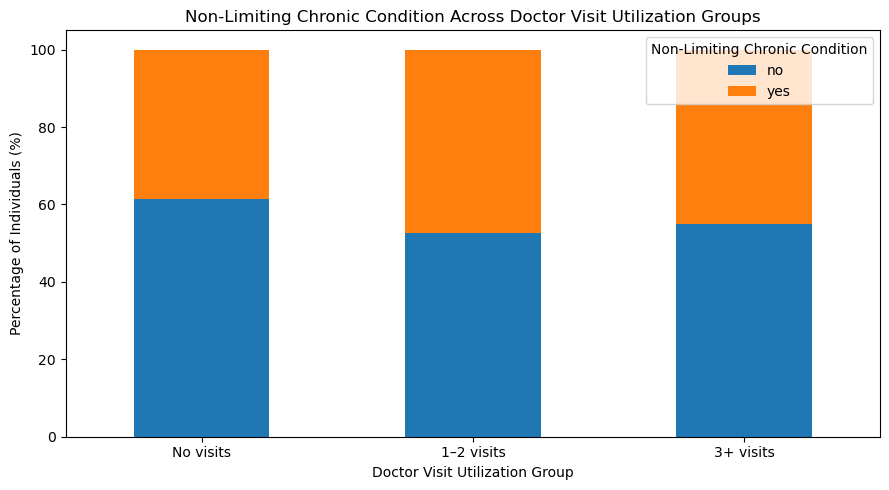

In [89]:
# Visualize non-limiting chronic condition composition across doctor visit utilization groups

nchronic_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5)
)

plt.title('Non-Limiting Chronic Condition Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Non-Limiting Chronic Condition')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that individuals without non-limiting chronic conditions make up the majority of each doctor visit utilization group, particularly among those with no visits (61.43%). However, individuals with such conditions represent a larger share of those with 1–2 visits (47.38%) and 3+ visits (45.16%), indicating a greater representation among individuals who utilize healthcare.</font>

### **9.3 How do doctor visits differ for individuals with activity-limiting chronic conditions?**

In [90]:
df['lchronic'].value_counts()

lchronic
no     4585
yes     605
Name: count, dtype: int64

In [91]:
# Calculate doctor visit statistics and the percentage of individuals with at least one doctor visit for each activity-limiting chronic condition group

lchronic_summary = df.groupby('lchronic').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
)

# Calculate the percentage of individuals with at least one doctor visit

lchronic_summary['Visit_Percentage'] = (
    lchronic_summary['Individuals_With_Visit']
    / lchronic_summary['Individuals'] * 100
).round(2)

lchronic_summary['Mean_Visits'] = (
    lchronic_summary['Mean_Visits'].round(2)
)

display(lchronic_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
lchronic,,,,,
no,4585,0.26,0.0,837,18.26
yes,605,0.60,0.0,212,35.04


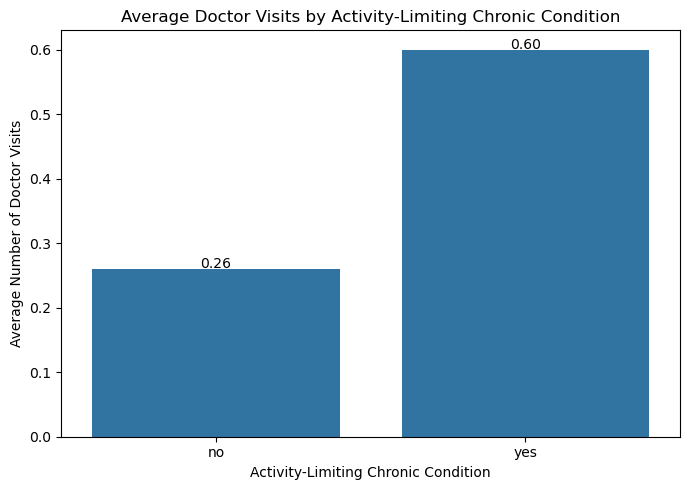

In [92]:
# Compare average doctor visits across activity-limiting chronic condition groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=lchronic_summary.reset_index(),
    x='lchronic',
    y='Mean_Visits'
)

plt.title('Average Doctor Visits by Activity-Limiting Chronic Condition')
plt.xlabel('Activity-Limiting Chronic Condition')
plt.ylabel('Average Number of Doctor Visits')

for i, value in enumerate(lchronic_summary['Mean_Visits']):
    ax.text(i, value + 0.001, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

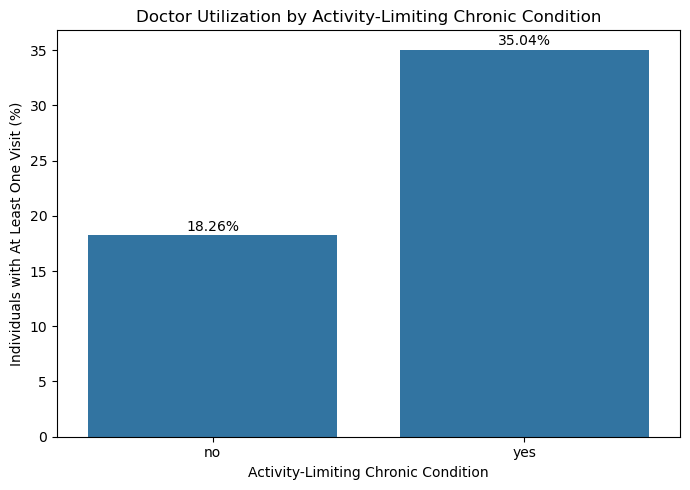

In [93]:
# Compare the percentage of individuals with at least one doctor visit across activity-limiting chronic condition groups

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    data=lchronic_summary.reset_index(),
    x='lchronic',
    y='Visit_Percentage'
)

plt.title('Doctor Utilization by Activity-Limiting Chronic Condition')
plt.xlabel('Activity-Limiting Chronic Condition')
plt.ylabel('Individuals with At Least One Visit (%)')

for i, value in enumerate(lchronic_summary['Visit_Percentage']):
    ax.text(i, value + 0.4, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graphs show that individuals with activity-limiting chronic conditions have higher healthcare utilization, with an average of 0.60 doctor visits and 35.04% reporting at least one visit, compared with 0.26 visits and 18.26% among those without such conditions. Overall, individuals with activity-limiting chronic conditions demonstrate greater observed doctor visit utilization in this dataset.</font>

### **9.4 What is the composition of activity-limiting chronic-condition status across utilization groups?**

In [94]:
# Calculate the percentage composition of activity-limiting chronic condition status within each doctor visit utilization group

lchronic_utilization = pd.crosstab(
    df['visit_group'],
    df['lchronic'],
    normalize='index'
) * 100

lchronic_utilization = lchronic_utilization.round(2)

display(lchronic_utilization)

lchronic,no,yes
visit_group,,
No visits,90.51,9.49
1–2 visits,80.75,19.25
3+ visits,69.89,30.11


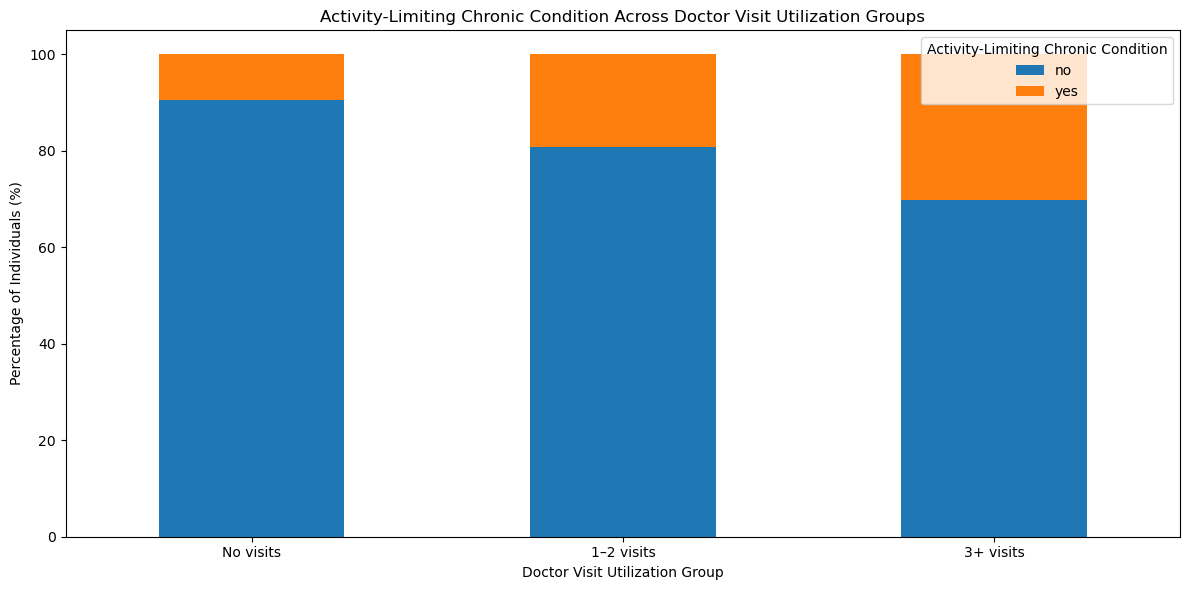

In [95]:
# Visualize activity-limiting chronic condition composition across doctor visit utilization groups

lchronic_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title('Activity-Limiting Chronic Condition Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Activity-Limiting Chronic Condition')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that individuals without activity-limiting chronic conditions form the majority across all utilization groups. However, their share decreases from 90.51% among those with no visits to 69.89% among those with 3+ visits, while the share of individuals with activity-limiting chronic conditions increases from 9.49% to 30.11%.</font>

### **9.5 How do healthcare utilization patterns vary across combined chronic-condition groups?**

In [96]:
# Combine the two chronic-condition indicators into four mutually exclusive groups for a more detailed chronic-condition analysis

df['chronic_group'] = np.select(
    [
        (df['nchronic'] == 'no') & (df['lchronic'] == 'no'),
        (df['nchronic'] == 'yes') & (df['lchronic'] == 'no'),
        (df['nchronic'] == 'no') & (df['lchronic'] == 'yes'),
        (df['nchronic'] == 'yes') & (df['lchronic'] == 'yes')
    ],
    [
        'No Chronic Condition',
        'Non-Limiting Only',
        'Activity-Limiting Only',
        'Both Chronic Conditions'
    ],
    default='Unknown'
)

# Define a logical order for the chronic-condition categories

chronic_order = [
    'No Chronic Condition',
    'Non-Limiting Only',
    'Activity-Limiting Only',
    'Both Chronic Conditions'
]

# Count individuals in each combined chronic-condition group and display the groups in the defined logical order

chronic_counts = df['chronic_group'].value_counts().reindex(chronic_order)

display(chronic_counts)

chronic_group
No Chronic Condition       2493.0
Non-Limiting Only          2092.0
Activity-Limiting Only      605.0
Both Chronic Conditions       NaN
Name: count, dtype: float64

In [97]:
# Calculate doctor visit statistics and the percentage of individuals with at least one doctor visit for each combined chronic condition group

chronic_summary = df.groupby('chronic_group').agg(
    Individuals=('visits', 'count'),
    Mean_Visits=('visits', 'mean'),
    Median_Visits=('visits', 'median'),
    Individuals_With_Visit=('visits', lambda x: (x > 0).sum())
).reindex(chronic_order)

# Calculate the percentage of individuals with at least one doctor visit

chronic_summary['Visit_Percentage'] = (
    chronic_summary['Individuals_With_Visit']
    / chronic_summary['Individuals'] * 100
).round(2)

chronic_summary['Mean_Visits'] = (
    chronic_summary['Mean_Visits'].round(2)
)

display(chronic_summary)

,Individuals,Mean_Visits,Median_Visits,Individuals_With_Visit,Visit_Percentage
chronic_group,,,,,
No Chronic Condition,2493.0,0.19,0.0,342.0,13.72
Non-Limiting Only,2092.0,0.35,0.0,495.0,23.66
Activity-Limiting Only,605.0,0.60,0.0,212.0,35.04
Both Chronic Conditions,NaN,NaN,NaN,NaN,NaN


posx and posy should be finite values
posx and posy should be finite values


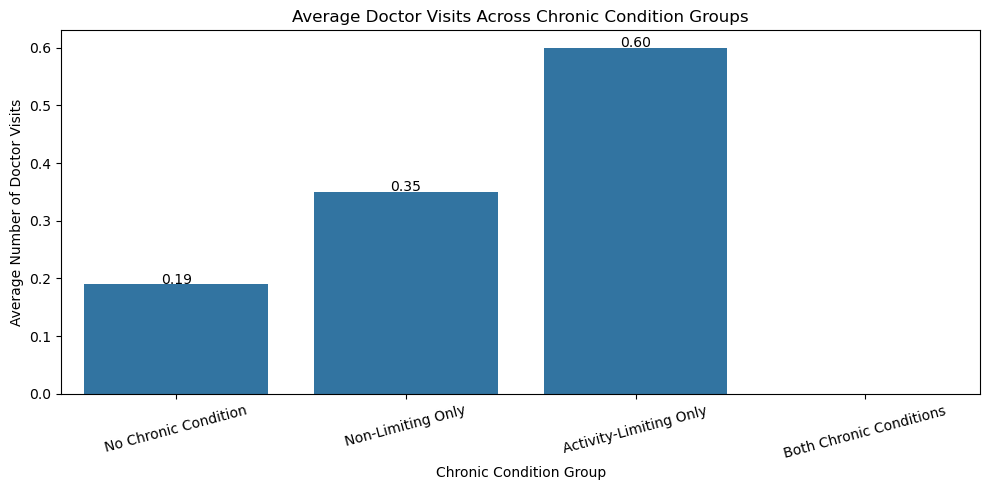

In [98]:
# Compare average doctor visits across the combined chronic condition groups

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=chronic_summary.reset_index(),
    x='chronic_group',
    y='Mean_Visits',
    order=chronic_order
)

plt.title('Average Doctor Visits Across Chronic Condition Groups')
plt.xlabel('Chronic Condition Group')
plt.ylabel('Average Number of Doctor Visits')
plt.xticks(rotation=15)

for i, value in enumerate(chronic_summary['Mean_Visits']):
    ax.text(i, value + 0.001, f'{value:.2f}', ha='center')

plt.tight_layout()
plt.show()

posx and posy should be finite values
posx and posy should be finite values


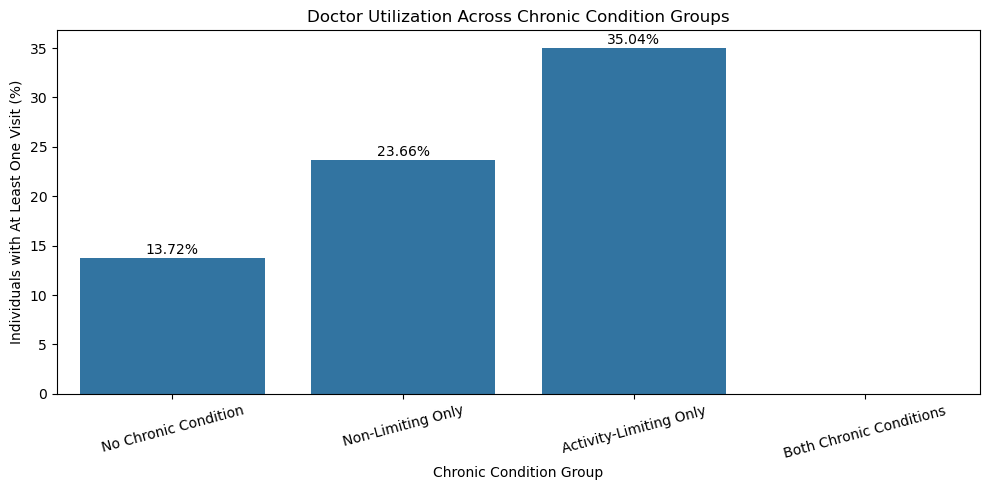

In [99]:
# Compare the percentage of individuals with at least one doctor visit across the combined chronic condition groups

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=chronic_summary.reset_index(),
    x='chronic_group',
    y='Visit_Percentage',
    order=chronic_order
)

plt.title('Doctor Utilization Across Chronic Condition Groups')
plt.xlabel('Chronic Condition Group')
plt.ylabel('Individuals with At Least One Visit (%)')
plt.xticks(rotation=15)

for i, value in enumerate(chronic_summary['Visit_Percentage']):
    ax.text(i, value + 0.4, f'{value:.2f}%', ha='center')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graphs show that healthcare utilization increases with chronic-condition severity. Individuals with activity-limiting chronic conditions have the highest average doctor visits (0.60) and visit percentage (35.04%), followed by those with non-limiting conditions (0.35 visits; 23.66%) and those with no chronic conditions (0.19 visits; 13.72%).</font>

### **9.6 What is the chronic-condition composition of each utilization group?**

In [100]:
# Calculate the percentage composition of combined chronic condition groups within each doctor visit utilization group

chronic_utilization = pd.crosstab(
    df['visit_group'],
    df['chronic_group'],
    normalize='index'
) * 100

chronic_utilization = chronic_utilization.round(2)

display(chronic_utilization)

chronic_group,Activity-Limiting Only,No Chronic Condition,Non-Limiting Only
visit_group,,,
No visits,9.49,51.94,38.57
1–2 visits,19.25,33.37,47.38
3+ visits,30.11,24.73,45.16


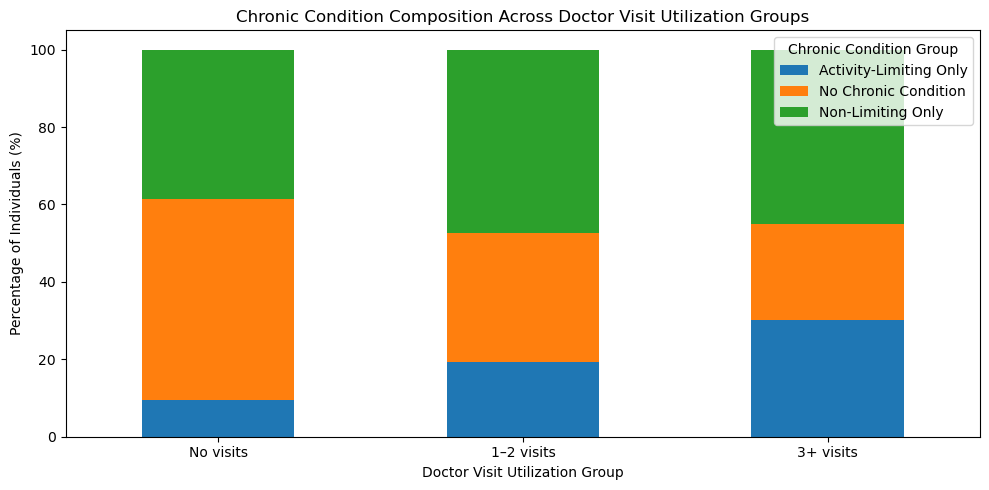

In [101]:
# Visualize chronic condition composition across doctor visit utilization groups

chronic_utilization.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 5)
)

plt.title('Chronic Condition Composition Across Doctor Visit Utilization Groups')
plt.xlabel('Doctor Visit Utilization Group')
plt.ylabel('Percentage of Individuals (%)')
plt.xticks(rotation=0)
plt.legend(title='Chronic Condition Group')

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that individuals with non-limiting chronic conditions form the largest share of the 1–2 visit (47.38%) and 3+ visit (45.16%) groups. Those with no chronic conditions dominate the no-visit group (51.94%), while the share with activity-limiting conditions increases from 9.49% among those with no visits to 30.11% among those with 3+ visits.</font>

> ### **10. OVERALL CORRELATION ANALYSIS**
### <font color = 'red'>**Analytical Questions:**</font>
### <font color = 'red'>**1. What are the relationships among the numeric features in the healthcare utilization dataset?**</font>
### <font color = 'red'>**2. Which numeric features have the strongest relationships with doctor visits?**</font>

### **10.1 What are the relationships among the numeric features in the healthcare utilization dataset?**

In [102]:
# Select the main numeric variables used for correlation analysis

numeric_cols = [
    'visits',
    'age_years',
    'annual_income',
    'illness',
    'reduced',
    'health'
]

# Calculate Pearson correlation coefficients between all selected numeric variables

correlation_matrix = df[numeric_cols].corr()

display(correlation_matrix.round(2))

,visits,age_years,annual_income,illness,reduced,health
visits,1.00,0.12,-0.08,0.22,0.42,0.19
age_years,0.12,1.00,-0.27,0.20,0.09,0.02
annual_income,-0.08,-0.27,1.00,-0.15,-0.05,-0.09
illness,0.22,0.20,-0.15,1.00,0.22,0.36
reduced,0.42,0.09,-0.05,0.22,1.00,0.28
health,0.19,0.02,-0.09,0.36,0.28,1.00


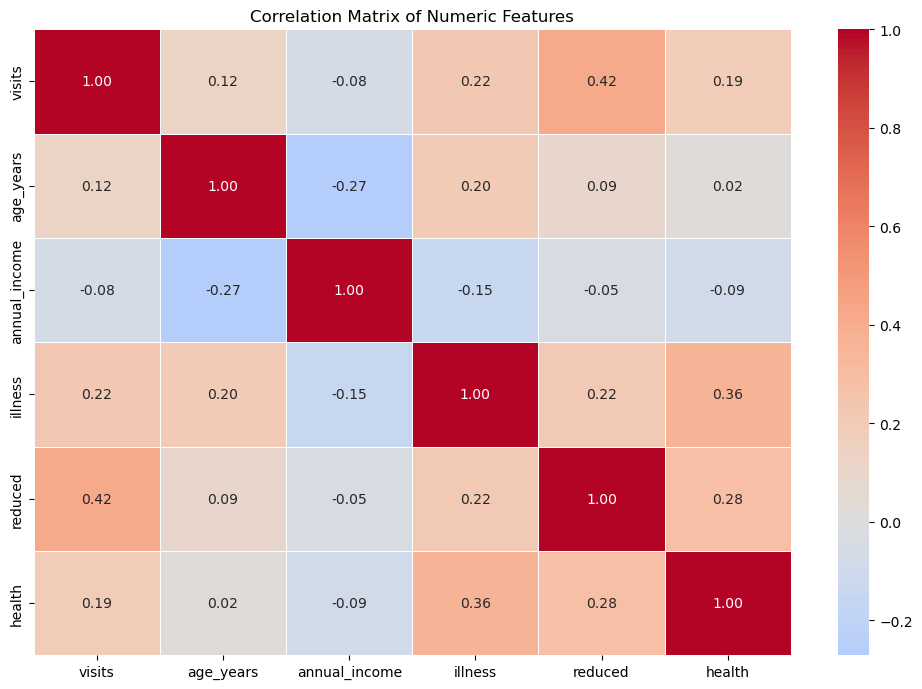

In [103]:
# Visualize the correlation coefficients to identify the direction and relative strength of linear relationships between numeric variables

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Matrix of Numeric Features')
plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above heatmap shows that doctor visits have the strongest positive correlation with reduced-activity days (0.42), while illness count is moderately correlated with health score (0.36). Annual income has a weak negative correlation with age (-0.27), and most other relationships are weak, indicating limited linear associations among the numeric features.</font>

### **10.2 Which numeric features have the strongest relationships with doctor visits?**

In [106]:
# Extract the correlations between doctor visits and the other numeric features, excluding visits itself

visit_correlations = (
    correlation_matrix['visits']
    .drop('visits')
    .sort_values(ascending=False)
)

display(visit_correlations.round(2))

reduced          0.42
illness          0.22
health           0.19
age_years        0.12
annual_income   -0.08
Name: visits, dtype: float64

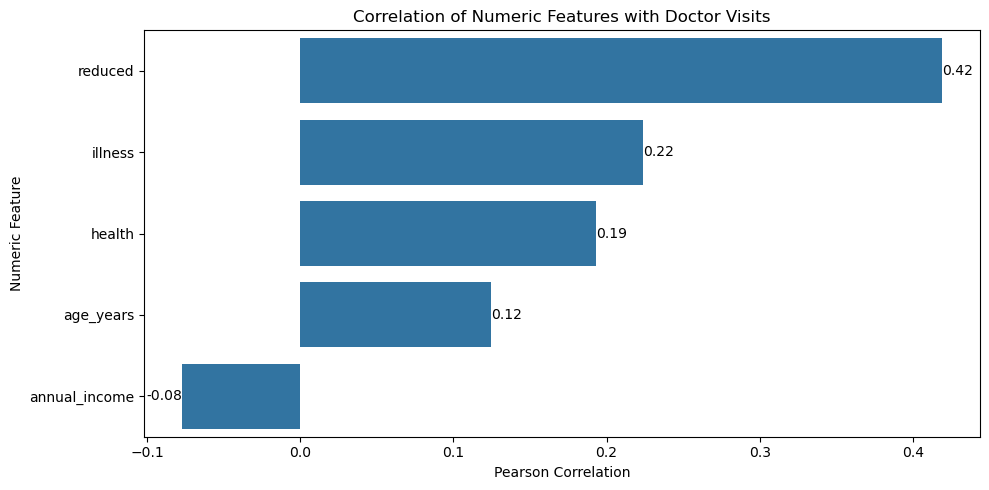

In [105]:
# Visualize the correlation of each numeric feature with doctor visits to make the relative strength and direction easier to compare

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=visit_correlations.values,
    y=visit_correlations.index
)

plt.title('Correlation of Numeric Features with Doctor Visits')
plt.xlabel('Pearson Correlation')
plt.ylabel('Numeric Feature')

for i, value in enumerate(visit_correlations.values):
    ax.text(
        value + 0.000001 if value >= 0 else value - 0.000001,
        i,
        f'{value:.2f}',
        va='center',
        ha='left' if value >= 0 else 'right'
    )

plt.tight_layout()
plt.show()

> ### <font color='green'>**Analytical Statement:**</font>
> ### <font color='green'>The above graph shows that reduced-activity days have the strongest positive relationship with doctor visits (0.42), followed by illness count (0.22) and health score (0.19). Age has a weak positive relationship (0.12), while annual income has a weak negative relationship (-0.08).</font>

> ### **11. KEY FINDINGS AND INSIGHTS**

### <font color='green'>1. Dataset: 5,190 individuals, no missing values. Duplicate-looking rows and outliers were kept as valid records.</font>
### <font color='green'>2. Utilization is concentrated at zero: 79.79% had no doctor visits, and only 20.21% had at least one (mean 0.30, median 0). The distribution is strongly right-skewed.</font>
### <font color='green'>3. Gender: Females average 0.36 visits versus 0.24 for males, and they make up about 64% of the 1–2 visit group.</font>
### <font color='green'>4. Age: Average visits rise from 0.22 (ages 19–30) to 0.43 (ages 61+). The share with at least one visit rises from 15.07% to 28.91%.</font>
### <font color='green'>5. Income: Average visits fall from 0.40 (low income) to 0.22 (high income). Low-income individuals make up the largest share of the 3+ visit group.</font>
### <font color='green'>6. Illness burden: Average illnesses rise from 1.26 (no visits) to 2.42 (3+ visits).</font>
### <font color='green'>7. Reduced activity: Average reduced-activity days rise from 0.43 to 7.75 across the same groups.</font>
### <font color='green'>8. Health score: The average rises from 1.02 to 3.06 as utilization increases.</font>
### <font color='green'>9. Private insurance: It makes little difference (0.29 vs 0.31 visits).</font>
### <font color='green'>10. Free care for low income: Recipients have lower use (0.16 vs 0.31 visits), but the group is very small.</font>
### <font color='green'>11. Free government care (freerepat): Recipients have higher use (0.47 vs 0.26 visits).</font>
### <font color='green'>12.Chronic conditions: Utilization rises with severity. Individuals with no chronic condition average 0.19 visits, and 13.72% have at least one visit. For those with non-limiting chronic conditions, the average is 0.35 visits and 23.66% have at least one visit. Those with activity-limiting chronic conditions have the highest utilization, at 0.60 visits on average and 35.04% with at least one visit.</font>
### <font color='green'>13. Correlation with visits: Reduced-activity days are the strongest at 0.42, then illness count (0.22), health score (0.19), age (0.12) and income (–0.08).</font>

> ### **12. CONCLUSION**

- ### <font color='green'>Doctor visits are rare, and a small high-need group drives most utilization.</font>
- ### <font color='green'>Health need is the strongest driver of visits. This means reduced-activity days, illness count and chronic conditions, especially activity-- limiting ones.</font>
- ### <font color='green'>Older people, women and lower-income individuals also use more care, but the effect is weaker.</font>
- ### <font color='green'>Insurance type has little impact on utilization.</font>
- ### <font color='green'>Recommendation: Prioritize older adults, chronic-condition patients and lower-income groups for care management and capacity planning.</font>
- ### <font color='green'>Limitation: These are associations, not causation. A count model such as zero-inflated Poisson or negative binomial is the next step.</font>